In [ ]:
# MULTI-TASK CNN ON FASHION-MNIST

# Imports and Setup
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision
from torchvision import transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, mean_absolute_error, mean_squared_error
import wandb
import os
from typing import Tuple, Dict, List
import warnings
warnings.filterwarnings('ignore')

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


WANDB_API_KEY = "4b42a6bb8776c07603c0f471b0e7e9ec4f936d66"
os.environ['WANDB_API_KEY'] = WANDB_API_KEY


# Dataset Loading and Custom Dataset
def load_fashion_data(data_dir='./data', train_ratio=0.9):
    """Load Fashion-MNIST and split into train, val, test."""
    train_full = torchvision.datasets.FashionMNIST(
        root=data_dir, train=True, download=True, transform=None
    )
    test_dataset = torchvision.datasets.FashionMNIST(
        root=data_dir, train=False, download=True, transform=None
    )
    
    train_size = int(train_ratio * len(train_full))
    val_size = len(train_full) - train_size
    train_dataset, val_dataset = random_split(
        train_full, [train_size, val_size], 
        generator=torch.Generator().manual_seed(42)
    )
    
    print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")
    return train_dataset, val_dataset, test_dataset


class FashionMNISTDataset(Dataset):
    """Custom Dataset returning (image, label, ink_target)."""
    
    def __init__(self, base_dataset, transform=None):
        self.base_dataset = base_dataset
        self.transform = transform
        self.mean, self.std = 0.2860, 0.3530
    
    def __len__(self):
        return len(self.base_dataset)
    
    def __getitem__(self, idx):
        if hasattr(self.base_dataset, 'dataset'):
            actual_idx = self.base_dataset.indices[idx]
            img_array = self.base_dataset.dataset.data[actual_idx].numpy()
            label = int(self.base_dataset.dataset.targets[actual_idx])
        else:
            img_array = self.base_dataset.data[idx].numpy()
            label = int(self.base_dataset.targets[idx])
        
        # CRITICAL FIX: Calculate ink from RAW pixel values BEFORE any transformations
        ink = float(img_array.mean() / 255.0)
        
        # Convert to PIL for transformations
        img = torchvision.transforms.ToPILImage()(img_array)
        
        if self.transform:
            img = self.transform(img)
        else:
            img = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize(mean=[self.mean], std=[self.std])
            ])(img)
        
        return img, label, torch.tensor(ink, dtype=torch.float32)


def get_transforms(is_train=False):
    """Get transformation pipeline."""
    mean, std = 0.2860, 0.3530
    if is_train:
        return transforms.Compose([
            transforms.RandomCrop(28, padding=2),
            transforms.RandomRotation(degrees=10),
            transforms.ToTensor(),
            transforms.Normalize(mean=[mean], std=[std])
        ])
    return transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=[mean], std=[std])
    ])


# Multi-Task CNN Model

class MultiTaskCNN(nn.Module):
    """Multi-Task CNN with configurable architecture."""
    
    def __init__(self, num_conv_blocks=3, channels=[32, 64, 128], dropout_rate=0.3):
        super(MultiTaskCNN, self).__init__()
        
        self.num_conv_blocks = num_conv_blocks
        self.channels = channels[:num_conv_blocks]
        
        self.conv_blocks = nn.ModuleList()
        in_channels = 1
        
        for i, out_channels in enumerate(self.channels):
            block = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2, 2),
                nn.Dropout2d(dropout_rate)
            )
            self.conv_blocks.append(block)
            in_channels = out_channels
        
        final_size = 28 // (2 ** num_conv_blocks)
        self.flatten_size = self.channels[-1] * final_size * final_size
        
        # Classification head
        self.fc_class1 = nn.Linear(self.flatten_size, 256)
        self.dropout_class = nn.Dropout(dropout_rate)
        self.fc_class2 = nn.Linear(256, 10)
        
        # Regression head
        self.fc_reg1 = nn.Linear(self.flatten_size, 128)
        self.dropout_reg = nn.Dropout(dropout_rate)
        self.fc_reg2 = nn.Linear(128, 1)
    
    def forward(self, x, return_features=False):
        feature_maps = []
        
        for block in self.conv_blocks:
            x = block(x)
            if return_features:
                feature_maps.append(x.clone())
        
        # Flatten
        x = x.view(x.size(0), -1)
        
        # Classification head
        class_x = F.relu(self.fc_class1(x))
        class_x = self.dropout_class(class_x)
        logits = self.fc_class2(class_x)
        
        # Regression head
        reg_x = F.relu(self.fc_reg1(x))
        reg_x = self.dropout_reg(reg_x)
        ink_pred = torch.sigmoid(self.fc_reg2(reg_x)).squeeze(1)
        
        if return_features:
            return logits, ink_pred, feature_maps
        return logits, ink_pred


# Loss and Training
def compute_joint_loss(logits, ink_pred, labels, ink_target, lambda1=1.0, lambda2=1.0):
    """Compute joint loss."""
    ce_loss = nn.CrossEntropyLoss()(logits, labels)
    mse_loss = nn.MSELoss()(ink_pred, ink_target)
    total_loss = lambda1 * ce_loss + lambda2 * mse_loss
    return total_loss, ce_loss, mse_loss


class Trainer:
    """Trainer for multi-task CNN."""
    
    def __init__(self, model, train_loader, val_loader, optimizer,
                 lambda1=1.0, lambda2=1.0, device='cuda'):
        self.model = model.to(device)
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.optimizer = optimizer
        self.lambda1 = lambda1
        self.lambda2 = lambda2
        self.device = device
        
        self.history = {
            'train_total_loss': [], 'train_ce_loss': [], 'train_mse_loss': [],
            'val_total_loss': [], 'val_ce_loss': [], 'val_mse_loss': [],
            'val_accuracy': [], 'val_mae': [], 'val_rmse': []
        }
        self.best_val_acc = 0.0
        self.best_val_rmse = float('inf')
    
    def train_epoch(self):
        self.model.train()
        total_loss_sum = ce_loss_sum = mse_loss_sum = 0.0
        num_batches = 0
        
        for images, labels, ink_targets in self.train_loader:
            images = images.to(self.device)
            labels = labels.to(self.device)
            ink_targets = ink_targets.to(self.device)
            
            self.optimizer.zero_grad()
            logits, ink_pred = self.model(images)
            total_loss, ce_loss, mse_loss = compute_joint_loss(
                logits, ink_pred, labels, ink_targets, self.lambda1, self.lambda2
            )
            total_loss.backward()
            self.optimizer.step()
            
            total_loss_sum += total_loss.item()
            ce_loss_sum += ce_loss.item()
            mse_loss_sum += mse_loss.item()
            num_batches += 1
        
        return (total_loss_sum / num_batches, ce_loss_sum / num_batches, 
                mse_loss_sum / num_batches)
    
    def validate(self):
        self.model.eval()
        total_loss_sum = ce_loss_sum = mse_loss_sum = 0.0
        num_batches = 0
        all_preds, all_labels, all_ink_preds, all_ink_targets = [], [], [], []
        
        with torch.no_grad():
            for images, labels, ink_targets in self.val_loader:
                images = images.to(self.device)
                labels = labels.to(self.device)
                ink_targets = ink_targets.to(self.device)
                
                logits, ink_pred = self.model(images)
                total_loss, ce_loss, mse_loss = compute_joint_loss(
                    logits, ink_pred, labels, ink_targets, self.lambda1, self.lambda2
                )
                
                total_loss_sum += total_loss.item()
                ce_loss_sum += ce_loss.item()
                mse_loss_sum += mse_loss.item()
                num_batches += 1
                
                preds = torch.argmax(logits, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
                all_ink_preds.extend(ink_pred.cpu().numpy())
                all_ink_targets.extend(ink_targets.cpu().numpy())
        
        accuracy = accuracy_score(all_labels, all_preds)
        mae = mean_absolute_error(all_ink_targets, all_ink_preds)
        rmse = np.sqrt(mean_squared_error(all_ink_targets, all_ink_preds))
        
        return (total_loss_sum / num_batches, ce_loss_sum / num_batches,
                mse_loss_sum / num_batches, accuracy, mae, rmse)
    
    def fit(self, num_epochs, save_path='best_model.pth'):
        print(f"Training for {num_epochs} epochs | λ1={self.lambda1}, λ2={self.lambda2}")
        
        for epoch in range(num_epochs):
            train_total, train_ce, train_mse = self.train_epoch()
            val_total, val_ce, val_mse, val_acc, val_mae, val_rmse = self.validate()
            
            self.history['train_total_loss'].append(train_total)
            self.history['train_ce_loss'].append(train_ce)
            self.history['train_mse_loss'].append(train_mse)
            self.history['val_total_loss'].append(val_total)
            self.history['val_ce_loss'].append(val_ce)
            self.history['val_mse_loss'].append(val_mse)
            self.history['val_accuracy'].append(val_acc)
            self.history['val_mae'].append(val_mae)
            self.history['val_rmse'].append(val_rmse)
            
            wandb.log({
                'epoch': epoch + 1,
                'train/total_loss': train_total, 'train/ce_loss': train_ce, 
                'train/mse_loss': train_mse,
                'val/total_loss': val_total, 'val/ce_loss': val_ce, 
                'val/mse_loss': val_mse,
                'val/accuracy': val_acc, 'val/mae': val_mae, 'val/rmse': val_rmse
            })
            
            print(f"Epoch {epoch+1}/{num_epochs} | "
                  f"Val Acc: {val_acc:.4f}, Val RMSE: {val_rmse:.4f}")
            
            if val_acc > self.best_val_acc:
                self.best_val_acc = val_acc
                torch.save(self.model.state_dict(), save_path)
            
            if val_rmse < self.best_val_rmse:
                self.best_val_rmse = val_rmse
        
        print(f"Best Val Acc: {self.best_val_acc:.4f}, Best Val RMSE: {self.best_val_rmse:.4f}\n")


# Evaluation and Visualization

def evaluate_model(model, test_loader, lambda1, lambda2, device='cuda'):
    """Evaluate on test set."""
    model.eval()
    total_loss_sum = ce_loss_sum = mse_loss_sum = 0.0
    num_batches = 0
    all_preds, all_labels, all_ink_preds, all_ink_targets = [], [], [], []
    
    with torch.no_grad():
        for images, labels, ink_targets in test_loader:
            images = images.to(device)
            labels = labels.to(device)
            ink_targets = ink_targets.to(device)
            
            logits, ink_pred = model(images)
            total_loss, ce_loss, mse_loss = compute_joint_loss(
                logits, ink_pred, labels, ink_targets, lambda1, lambda2
            )
            
            total_loss_sum += total_loss.item()
            ce_loss_sum += ce_loss.item()
            mse_loss_sum += mse_loss.item()
            num_batches += 1
            
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_ink_preds.extend(ink_pred.cpu().numpy())
            all_ink_targets.extend(ink_targets.cpu().numpy())
    
    return {
        'test_total_loss': total_loss_sum / num_batches,
        'test_ce_loss': ce_loss_sum / num_batches,
        'test_mse_loss': mse_loss_sum / num_batches,
        'test_accuracy': accuracy_score(all_labels, all_preds),
        'test_mae': mean_absolute_error(all_ink_targets, all_ink_preds),
        'test_rmse': np.sqrt(mean_squared_error(all_ink_targets, all_ink_preds)),
        'predictions': all_preds,
        'labels': all_labels
    }


def plot_confusion_matrix(labels, predictions, save_path=None):
    """Plot confusion matrix."""
    class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
                   'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
    cm = confusion_matrix(labels, predictions)
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted', fontsize=12)
    plt.ylabel('True', fontsize=12)
    plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        wandb.log({"confusion_matrix": wandb.Image(plt.gcf())})
    plt.show()


# Experiment Runner
def run_experiment(config, train_dataset, val_dataset, test_dataset):
    """Run single experiment with given config."""
    run_name = config['run_name']
    wandb.init(project="SMAI_A4_Q1_MultiTask_re_run", name=run_name, config=config, reinit=True)
    
    print(f"\n{'='*80}\n{run_name}\n{'='*80}")
    
    train_ds = FashionMNISTDataset(train_dataset, transform=get_transforms(is_train=True))
    val_ds = FashionMNISTDataset(val_dataset, transform=get_transforms(is_train=False))
    test_ds = FashionMNISTDataset(test_dataset, transform=get_transforms(is_train=False))
    
    # data loaders
    train_loader = DataLoader(train_ds, batch_size=config['batch_size'],
                             shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=config['batch_size'],
                           shuffle=False, num_workers=2, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=config['batch_size'],
                            shuffle=False, num_workers=2, pin_memory=True)
    
    # model
    model = MultiTaskCNN(
        num_conv_blocks=config['num_conv_blocks'],
        channels=config['channels'],
        dropout_rate=config['dropout']
    )
    
    # optimizer
    if config['optimizer'] == 'Adam':
        optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'])
    elif config['optimizer'] == 'AdamW':
        optimizer = torch.optim.AdamW(model.parameters(), lr=config['lr'], weight_decay=1e-4)
    else:
        optimizer = torch.optim.SGD(model.parameters(), lr=config['lr'], momentum=0.9)
    
    # Train
    trainer = Trainer(model, train_loader, val_loader, optimizer,
                     config['lambda1'], config['lambda2'], device)
    
    os.makedirs('models', exist_ok=True)
    save_path = f"models/{run_name.replace(' ', '_').replace(':', '_')}.pth"
    trainer.fit(config['epochs'], save_path)
    
    # Load best model and evaluate
    trainer.model.load_state_dict(torch.load(save_path))
    test_metrics = evaluate_model(trainer.model, test_loader,
                                  config['lambda1'], config['lambda2'], device)
    
    print(f"TEST RESULTS: Acc={test_metrics['test_accuracy']:.4f}, "
          f"MAE={test_metrics['test_mae']:.4f}, RMSE={test_metrics['test_rmse']:.4f}")
    
    wandb.log({
        'test/accuracy': test_metrics['test_accuracy'],
        'test/mae': test_metrics['test_mae'],
        'test/rmse': test_metrics['test_rmse']
    })
    
    wandb.finish()
    return trainer, test_metrics


# Load Data
print("Loading Fashion-MNIST dataset...")
train_dataset, val_dataset, test_dataset = load_fashion_data()

Using device: cuda
Loading Fashion-MNIST dataset...
Train: 54000, Val: 6000, Test: 10000


In [59]:
os.makedirs('plots', exist_ok=True)


EXPERIMENT 1: LAMBDA RATIO EXPLORATION



Lambda_Lambda 1:1 (Balanced)
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8232, Val RMSE: 0.0376
Epoch 2/5 | Val Acc: 0.8452, Val RMSE: 0.0376
Epoch 3/5 | Val Acc: 0.8660, Val RMSE: 0.0344
Epoch 4/5 | Val Acc: 0.8687, Val RMSE: 0.0356
Epoch 5/5 | Val Acc: 0.8760, Val RMSE: 0.0353
Best Val Acc: 0.8760, Best Val RMSE: 0.0344

TEST RESULTS: Acc=0.8720, MAE=0.0251, RMSE=0.0351


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▂▁
train/mse_loss,█▂▁▁▁
train/total_loss,█▃▂▂▁
val/accuracy,▁▄▇▇█
val/ce_loss,█▄▁▁▁
val/mae,██▁▃▂
val/mse_loss,██▁▄▃



Lambda_Lambda 2:1 (Class Focus)
Training for 5 epochs | λ1=2.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8282, Val RMSE: 0.0395
Epoch 2/5 | Val Acc: 0.8570, Val RMSE: 0.0355
Epoch 3/5 | Val Acc: 0.8718, Val RMSE: 0.0358
Epoch 4/5 | Val Acc: 0.8752, Val RMSE: 0.0345
Epoch 5/5 | Val Acc: 0.8828, Val RMSE: 0.0320
Best Val Acc: 0.8828, Best Val RMSE: 0.0320

TEST RESULTS: Acc=0.8813, MAE=0.0237, RMSE=0.0318


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,█▃▂▁▁
train/total_loss,█▃▂▁▁
val/accuracy,▁▅▇▇█
val/ce_loss,█▅▃▂▁
val/mae,█▄▄▃▁
val/mse_loss,█▄▄▃▁



Lambda_Lambda 1:2 (Regression Focus)
Training for 5 epochs | λ1=1.0, λ2=2.0
Epoch 1/5 | Val Acc: 0.8210, Val RMSE: 0.0345
Epoch 2/5 | Val Acc: 0.8528, Val RMSE: 0.0390
Epoch 3/5 | Val Acc: 0.8632, Val RMSE: 0.0372
Epoch 4/5 | Val Acc: 0.8782, Val RMSE: 0.0393
Epoch 5/5 | Val Acc: 0.8778, Val RMSE: 0.0343
Best Val Acc: 0.8782, Best Val RMSE: 0.0343

TEST RESULTS: Acc=0.8741, MAE=0.0299, RMSE=0.0399


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▂▁
train/mse_loss,█▂▂▁▁
train/total_loss,█▃▂▂▁
val/accuracy,▁▅▆██
val/ce_loss,█▄▂▁▁
val/mae,▂█▄█▁
val/mse_loss,▁█▅█▁



LAMBDA EXPLORATION RESULTS
Configuration                  λ1:λ2      Test Acc     Test RMSE   
--------------------------------------------------------------------------------
Lambda 1:1 (Balanced)          1.0:1.0    0.8720       0.0351      
Lambda 2:1 (Class Focus)       2.0:1.0    0.8813       0.0318      
Lambda 1:2 (Regression Focus)  1.0:2.0    0.8741       0.0399      

Saved plot: plots/lambda_comparison.png


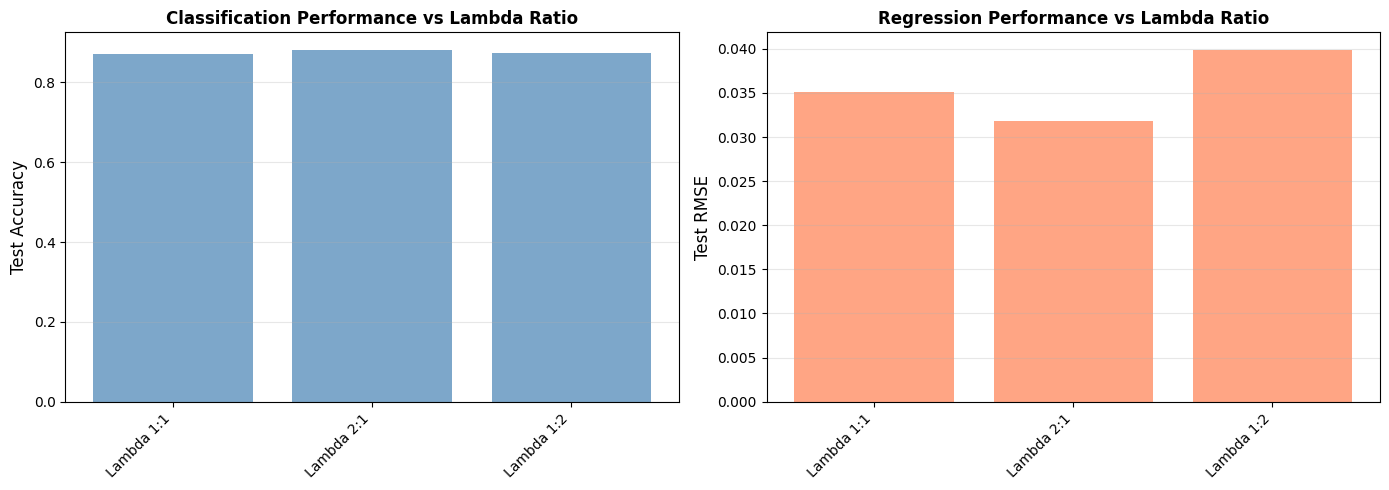

In [ ]:

# Experiment 1 - Lambda Ratio Exploration
# Base configuration
base_config = {
    'batch_size': 128,
    'num_conv_blocks': 3,
    'channels': [32, 64, 128],
    'dropout': 0.3,
    'lr': 0.001,
    'optimizer': 'Adam',
    'epochs': 5
}

# Lambda configurations
lambda_configs = [
    {'lambda1': 1.0, 'lambda2': 1.0, 'name': 'Lambda 1:1 (Balanced)'},
    {'lambda1': 2.0, 'lambda2': 1.0, 'name': 'Lambda 2:1 (Class Focus)'},
    {'lambda1': 1.0, 'lambda2': 2.0, 'name': 'Lambda 1:2 (Regression Focus)'},
]

lambda_results = []

print("\n" + "="*80)
print("EXPERIMENT 1: LAMBDA RATIO EXPLORATION")
print("="*80)

for lambda_config in lambda_configs:
    config = {**base_config, 
              'lambda1': lambda_config['lambda1'],
              'lambda2': lambda_config['lambda2'],
              'run_name': f"Lambda_{lambda_config['name']}"}
    
    trainer, metrics = run_experiment(config, train_dataset, val_dataset, test_dataset)
    lambda_results.append({
        'name': lambda_config['name'],
        'lambda1': lambda_config['lambda1'],
        'lambda2': lambda_config['lambda2'],
        'trainer': trainer,
        'metrics': metrics
    })

print("\n" + "="*80)
print("LAMBDA EXPLORATION RESULTS")
print("="*80)
print(f"{'Configuration':<30} {'λ1:λ2':<10} {'Test Acc':<12} {'Test RMSE':<12}")
print("-"*80)
for result in lambda_results:
    ratio = f"{result['lambda1']}:{result['lambda2']}"
    print(f"{result['name']:<30} {ratio:<10} "
          f"{result['metrics']['test_accuracy']:<12.4f} "
          f"{result['metrics']['test_rmse']:<12.4f}")
print("="*80 + "\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
names = [r['name'].split('(')[0].strip() for r in lambda_results]
accuracies = [r['metrics']['test_accuracy'] for r in lambda_results]
rmses = [r['metrics']['test_rmse'] for r in lambda_results]

axes[0].bar(range(len(names)), accuracies, color='steelblue', alpha=0.7)
axes[0].set_xticks(range(len(names)))
axes[0].set_xticklabels(names, rotation=45, ha='right')
axes[0].set_ylabel('Test Accuracy', fontsize=12)
axes[0].set_title('Classification Performance vs Lambda Ratio', fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(range(len(names)), rmses, color='coral', alpha=0.7)
axes[1].set_xticks(range(len(names)))
axes[1].set_xticklabels(names, rotation=45, ha='right')
axes[1].set_ylabel('Test RMSE', fontsize=12)
axes[1].set_title('Regression Performance vs Lambda Ratio', fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
os.makedirs('plots', exist_ok=True)
save_path = 'plots/lambda_comparison.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved plot: {save_path}")

# Log to wandb
wandb.init(project="SMAI_A4_Q1_MultiTask_re_run", name="Lambda_Comparison_Plot", reinit=True)
wandb.log({"lambda_comparison": wandb.Image(fig)})
wandb.finish()
plt.show()


EXPERIMENT 2: LEARNING RATE EXPLORATION



LR_LR 0.0001 (Very Low)
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.7493, Val RMSE: 0.0495
Epoch 2/5 | Val Acc: 0.7870, Val RMSE: 0.0387
Epoch 3/5 | Val Acc: 0.8113, Val RMSE: 0.0421
Epoch 4/5 | Val Acc: 0.8177, Val RMSE: 0.0376
Epoch 5/5 | Val Acc: 0.8410, Val RMSE: 0.0323
Best Val Acc: 0.8410, Best Val RMSE: 0.0323

TEST RESULTS: Acc=0.8391, MAE=0.0249, RMSE=0.0326


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,█▃▂▁▁
train/total_loss,█▃▂▁▁
val/accuracy,▁▄▆▆█
val/ce_loss,█▅▃▂▁
val/mae,█▄▅▃▁
val/mse_loss,█▃▅▃▁



LR_LR 0.0005 (Low)
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8050, Val RMSE: 0.0365
Epoch 2/5 | Val Acc: 0.8453, Val RMSE: 0.0331
Epoch 3/5 | Val Acc: 0.8570, Val RMSE: 0.0357
Epoch 4/5 | Val Acc: 0.8723, Val RMSE: 0.0339
Epoch 5/5 | Val Acc: 0.8792, Val RMSE: 0.0312
Best Val Acc: 0.8792, Best Val RMSE: 0.0312

TEST RESULTS: Acc=0.8758, MAE=0.0235, RMSE=0.0311


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,█▃▂▁▁
train/total_loss,█▃▂▁▁
val/accuracy,▁▅▆▇█
val/ce_loss,█▅▄▁▁
val/mae,█▄▆▅▁
val/mse_loss,█▃▇▄▁


...

Epoch 5/5 | Val Acc: 0.8767, Val RMSE: 0.3163
Best Val Acc: 0.8767, Best Val RMSE: 0.3163

TEST RESULTS: Acc=0.8766, MAE=0.2868, RMSE=0.3132


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,▁▁▁█▁
train/total_loss,█▃▂▁▁
val/accuracy,▁▅▇██
val/ce_loss,█▄▂▁▁
val/mae,██▁██
val/mse_loss,██▁██



LR_LR 0.01 (Very High)
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.7953, Val RMSE: 0.3163
Epoch 2/5 | Val Acc: 0.8243, Val RMSE: 0.3163
Epoch 3/5 | Val Acc: 0.8303, Val RMSE: 0.3163
Epoch 4/5 | Val Acc: 0.8553, Val RMSE: 0.3163
Epoch 5/5 | Val Acc: 0.8533, Val RMSE: 0.3163
Best Val Acc: 0.8553, Best Val RMSE: 0.3163

TEST RESULTS: Acc=0.8592, MAE=0.2868, RMSE=0.3132


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,▁████
train/total_loss,█▃▂▁▁
val/accuracy,▁▄▅██
val/ce_loss,█▅▄▁▂
val/mae,████▁
val/mse_loss,███▇▁



LEARNING RATE EXPLORATION RESULTS
Configuration                  LR           Test Acc     Test RMSE   
--------------------------------------------------------------------------------
LR 0.0001 (Very Low)           0.000100     0.8391       0.0326      
LR 0.0005 (Low)                0.000500     0.8758       0.0311      
LR 0.001 (Medium)              0.001000     0.8820       0.0298      
LR 0.005 (High)                0.005000     0.8766       0.3132      
LR 0.01 (Very High)            0.010000     0.8592       0.3132      

Saved plot: plots/lr_comparison.png


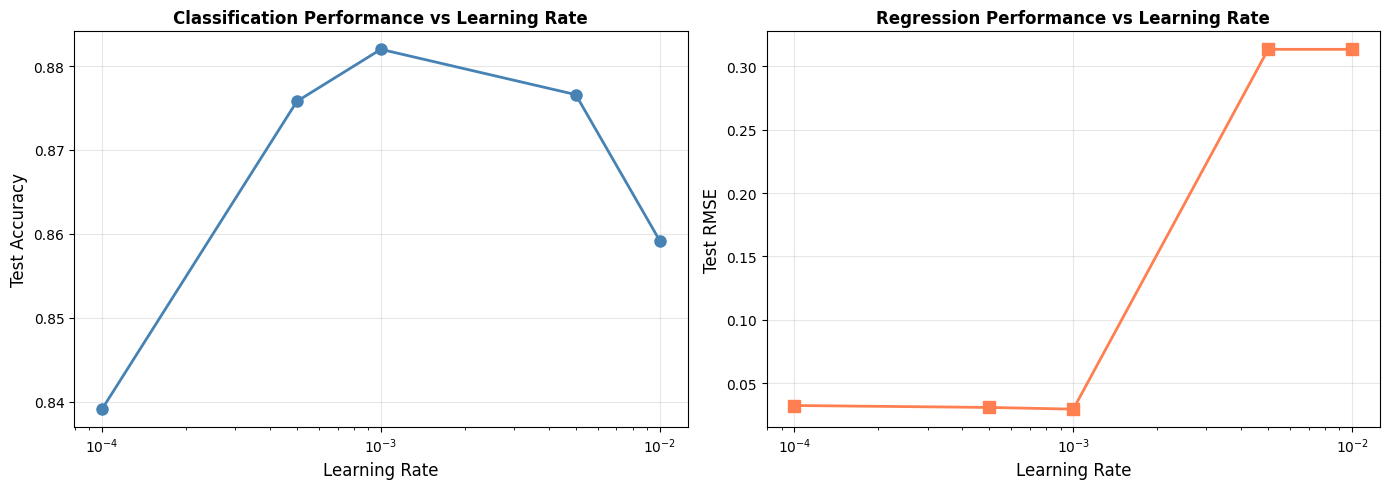

In [ ]:
# Experiment 2 - Learning Rate Exploration
"""
Explore different learning rates while keeping lambda balanced (1:1)
and other parameters constant.
"""

lr_configs = [
    {'lr': 0.0001, 'name': 'LR 0.0001 (Very Low)'},
    {'lr': 0.0005, 'name': 'LR 0.0005 (Low)'},
    {'lr': 0.001, 'name': 'LR 0.001 (Medium)'},
    {'lr': 0.005, 'name': 'LR 0.005 (High)'},
    {'lr': 0.01, 'name': 'LR 0.01 (Very High)'},
]

lr_results = []

print("\n" + "="*80)
print("EXPERIMENT 2: LEARNING RATE EXPLORATION")
print("="*80)

for lr_config in lr_configs:
    config = {**base_config,
              'lambda1': 1.0, 'lambda2': 1.0,
              'lr': lr_config['lr'],
              'run_name': f"LR_{lr_config['name']}"}
    
    trainer, metrics = run_experiment(config, train_dataset, val_dataset, test_dataset)
    lr_results.append({
        'name': lr_config['name'],
        'lr': lr_config['lr'],
        'trainer': trainer,
        'metrics': metrics
    })

# Print LR Comparison
print("\n" + "="*80)
print("LEARNING RATE EXPLORATION RESULTS")
print("="*80)
print(f"{'Configuration':<30} {'LR':<12} {'Test Acc':<12} {'Test RMSE':<12}")
print("-"*80)
for result in lr_results:
    print(f"{result['name']:<30} {result['lr']:<12.6f} "
          f"{result['metrics']['test_accuracy']:<12.4f} "
          f"{result['metrics']['test_rmse']:<12.4f}")
print("="*80 + "\n")

# Plot LR Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

lrs = [r['lr'] for r in lr_results]
accuracies = [r['metrics']['test_accuracy'] for r in lr_results]
rmses = [r['metrics']['test_rmse'] for r in lr_results]

axes[0].plot(lrs, accuracies, 'o-', color='steelblue', linewidth=2, markersize=8)
axes[0].set_xscale('log')
axes[0].set_xlabel('Learning Rate', fontsize=12)
axes[0].set_ylabel('Test Accuracy', fontsize=12)
axes[0].set_title('Classification Performance vs Learning Rate', fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(lrs, rmses, 's-', color='coral', linewidth=2, markersize=8)
axes[1].set_xscale('log')
axes[1].set_xlabel('Learning Rate', fontsize=12)
axes[1].set_ylabel('Test RMSE', fontsize=12)
axes[1].set_title('Regression Performance vs Learning Rate', fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
save_path = 'plots/lr_comparison.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved plot: {save_path}")

# Log to wandb
wandb.init(project="SMAI_A4_Q1_MultiTask_re_run", name="LR_Comparison_Plot", reinit=True)
wandb.log({"lr_comparison": wandb.Image(fig)})
wandb.finish()

plt.show()


EXPERIMENT 3: DROPOUT RATE EXPLORATION



Dropout_Dropout 0.1 (Low)
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8547, Val RMSE: 0.0260
Epoch 2/5 | Val Acc: 0.8732, Val RMSE: 0.0237
Epoch 3/5 | Val Acc: 0.8842, Val RMSE: 0.0221
Epoch 4/5 | Val Acc: 0.8940, Val RMSE: 0.0238
Epoch 5/5 | Val Acc: 0.9002, Val RMSE: 0.0258
Best Val Acc: 0.9002, Best Val RMSE: 0.0221

TEST RESULTS: Acc=0.9020, MAE=0.0195, RMSE=0.0256


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▂▁
train/mse_loss,█▂▁▁▁
train/total_loss,█▃▂▂▁
val/accuracy,▁▄▆▇█
val/ce_loss,█▅▃▂▁
val/mae,█▄▁▄▇
val/mse_loss,█▄▁▄█



Dropout_Dropout 0.3 (Medium)
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8192, Val RMSE: 0.0364
Epoch 2/5 | Val Acc: 0.8615, Val RMSE: 0.0333
Epoch 3/5 | Val Acc: 0.8648, Val RMSE: 0.0325
Epoch 4/5 | Val Acc: 0.8770, Val RMSE: 0.0312
Epoch 5/5 | Val Acc: 0.8822, Val RMSE: 0.0336
Best Val Acc: 0.8822, Best Val RMSE: 0.0312

TEST RESULTS: Acc=0.8826, MAE=0.0256, RMSE=0.0332


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▂▁
train/mse_loss,█▂▂▁▁
train/total_loss,█▃▂▂▁
val/accuracy,▁▆▆▇█
val/ce_loss,█▄▃▁▁
val/mae,█▃▂▁▃
val/mse_loss,█▄▃▁▄



Dropout_Dropout 0.5 (High)
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.7820, Val RMSE: 0.0559
Epoch 2/5 | Val Acc: 0.8035, Val RMSE: 0.0477
Epoch 3/5 | Val Acc: 0.8063, Val RMSE: 0.0508
Epoch 4/5 | Val Acc: 0.8343, Val RMSE: 0.0480
Epoch 5/5 | Val Acc: 0.8498, Val RMSE: 0.0479
Best Val Acc: 0.8498, Best Val RMSE: 0.0477

TEST RESULTS: Acc=0.8445, MAE=0.0357, RMSE=0.0480


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,█▃▂▁▁
train/total_loss,█▃▂▁▁
val/accuracy,▁▃▄▆█
val/ce_loss,█▆▅▃▁
val/mae,█▂▄▂▁
val/mse_loss,█▁▄▁▁



Dropout_Dropout 0.7 (Very High)
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.6978, Val RMSE: 0.0654
Epoch 2/5 | Val Acc: 0.7520, Val RMSE: 0.0629
Epoch 3/5 | Val Acc: 0.7650, Val RMSE: 0.0611
Epoch 4/5 | Val Acc: 0.7623, Val RMSE: 0.0607
Epoch 5/5 | Val Acc: 0.7683, Val RMSE: 0.0635
Best Val Acc: 0.7683, Best Val RMSE: 0.0607

TEST RESULTS: Acc=0.7628, MAE=0.0499, RMSE=0.0637


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,█▃▂▁▁
train/total_loss,█▃▂▁▁
val/accuracy,▁▆█▇█
val/ce_loss,█▃▂▁▁
val/mae,█▄▂▁▄
val/mse_loss,█▄▂▁▅



DROPOUT RATE EXPLORATION RESULTS
Configuration                  Dropout      Test Acc     Test RMSE   
--------------------------------------------------------------------------------
Dropout 0.1 (Low)              0.10         0.9020       0.0256      
Dropout 0.3 (Medium)           0.30         0.8826       0.0332      
Dropout 0.5 (High)             0.50         0.8445       0.0480      
Dropout 0.7 (Very High)        0.70         0.7628       0.0637      

Saved plot: plots/dropout_comparison.png


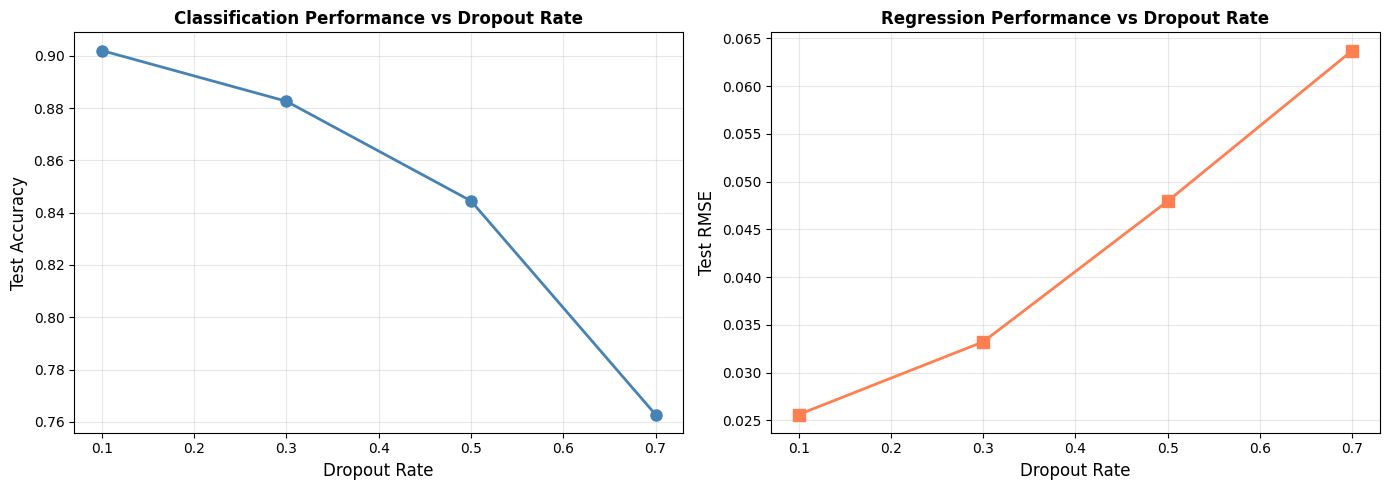

In [ ]:
# Experiment 3 - Dropout Rate Exploration

"""
Explore different dropout rates for regularization.
"""

dropout_configs = [
    {'dropout': 0.1, 'name': 'Dropout 0.1 (Low)'},
    {'dropout': 0.3, 'name': 'Dropout 0.3 (Medium)'},
    {'dropout': 0.5, 'name': 'Dropout 0.5 (High)'},
    {'dropout': 0.7, 'name': 'Dropout 0.7 (Very High)'},
]

dropout_results = []

print("\n" + "="*80)
print("EXPERIMENT 3: DROPOUT RATE EXPLORATION")
print("="*80)

for dropout_config in dropout_configs:
    config = {**base_config,
              'lambda1': 1.0, 'lambda2': 1.0,
              'dropout': dropout_config['dropout'],
              'run_name': f"Dropout_{dropout_config['name']}"}
    
    trainer, metrics = run_experiment(config, train_dataset, val_dataset, test_dataset)
    dropout_results.append({
        'name': dropout_config['name'],
        'dropout': dropout_config['dropout'],
        'trainer': trainer,
        'metrics': metrics
    })

print("\n" + "="*80)
print("DROPOUT RATE EXPLORATION RESULTS")
print("="*80)
print(f"{'Configuration':<30} {'Dropout':<12} {'Test Acc':<12} {'Test RMSE':<12}")
print("-"*80)
for result in dropout_results:
    print(f"{result['name']:<30} {result['dropout']:<12.2f} "
          f"{result['metrics']['test_accuracy']:<12.4f} "
          f"{result['metrics']['test_rmse']:<12.4f}")
print("="*80 + "\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

dropouts = [r['dropout'] for r in dropout_results]
accuracies = [r['metrics']['test_accuracy'] for r in dropout_results]
rmses = [r['metrics']['test_rmse'] for r in dropout_results]

axes[0].plot(dropouts, accuracies, 'o-', color='steelblue', linewidth=2, markersize=8)
axes[0].set_xlabel('Dropout Rate', fontsize=12)
axes[0].set_ylabel('Test Accuracy', fontsize=12)
axes[0].set_title('Classification Performance vs Dropout Rate', fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(dropouts, rmses, 's-', color='coral', linewidth=2, markersize=8)
axes[1].set_xlabel('Dropout Rate', fontsize=12)
axes[1].set_ylabel('Test RMSE', fontsize=12)
axes[1].set_title('Regression Performance vs Dropout Rate', fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
save_path = 'plots/dropout_comparison.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved plot: {save_path}")

wandb.init(project="SMAI_A4_Q1_MultiTask_re_run", name="Dropout_Comparison_Plot", reinit=True)
wandb.log({"dropout_comparison": wandb.Image(fig)})
wandb.finish()

plt.show()


EXPERIMENT 4: OPTIMIZER COMPARISON



Optimizer_SGD
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.7262, Val RMSE: 0.0636
Epoch 2/5 | Val Acc: 0.7398, Val RMSE: 0.0576
Epoch 3/5 | Val Acc: 0.7680, Val RMSE: 0.0546
Epoch 4/5 | Val Acc: 0.7847, Val RMSE: 0.0518
Epoch 5/5 | Val Acc: 0.7923, Val RMSE: 0.0507
Best Val Acc: 0.7923, Best Val RMSE: 0.0507

TEST RESULTS: Acc=0.7900, MAE=0.0404, RMSE=0.0512


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,█▃▂▁▁
train/total_loss,█▃▂▁▁
val/accuracy,▁▂▅▇█
val/ce_loss,█▅▃▂▁
val/mae,█▄▃▂▁
val/mse_loss,█▅▃▂▁



Optimizer_Adam
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8162, Val RMSE: 0.0417
Epoch 2/5 | Val Acc: 0.8545, Val RMSE: 0.0384
Epoch 3/5 | Val Acc: 0.8615, Val RMSE: 0.0393
Epoch 4/5 | Val Acc: 0.8712, Val RMSE: 0.0355
Epoch 5/5 | Val Acc: 0.8843, Val RMSE: 0.0354
Best Val Acc: 0.8843, Best Val RMSE: 0.0354

TEST RESULTS: Acc=0.8855, MAE=0.0248, RMSE=0.0351


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,█▂▁▁▁
train/total_loss,█▃▂▁▁
val/accuracy,▁▅▆▇█
val/ce_loss,█▅▄▂▁
val/mae,█▄▅▁▁
val/mse_loss,█▄▅▁▁



Optimizer_AdamW
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8212, Val RMSE: 0.0361
Epoch 2/5 | Val Acc: 0.8505, Val RMSE: 0.0369
Epoch 3/5 | Val Acc: 0.8647, Val RMSE: 0.0424
Epoch 4/5 | Val Acc: 0.8798, Val RMSE: 0.0361
Epoch 5/5 | Val Acc: 0.8795, Val RMSE: 0.0366
Best Val Acc: 0.8798, Best Val RMSE: 0.0361

TEST RESULTS: Acc=0.8757, MAE=0.0255, RMSE=0.0363


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▄▂▂▁
train/mse_loss,█▂▂▁▁
train/total_loss,█▃▂▂▁
val/accuracy,▁▄▆██
val/ce_loss,█▅▃▂▁
val/mae,▃▂█▁▁
val/mse_loss,▁▂█▁▂



OPTIMIZER EXPLORATION RESULTS
Optimizer                      Test Acc     Test RMSE    Test Loss   
--------------------------------------------------------------------------------
SGD                            0.7900       0.0512       0.5435      
Adam                           0.8855       0.0351       0.3177      
AdamW                          0.8757       0.0363       0.3384      

Saved plot: plots/optimizer_comparison.png


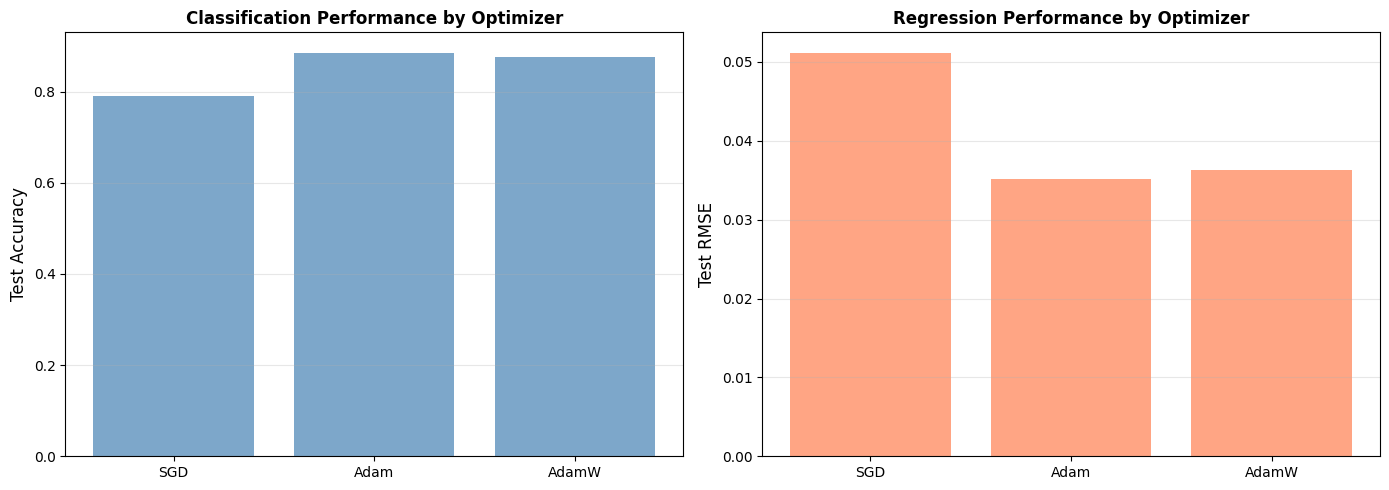

In [ ]:
# Experiment 4 - Optimizer Comparison
"""
Compare different optimizers: SGD, Adam, AdamW
"""

optimizer_configs = [
    {'optimizer': 'SGD', 'name': 'SGD'},
    {'optimizer': 'Adam', 'name': 'Adam'},
    {'optimizer': 'AdamW', 'name': 'AdamW'},
]

optimizer_results = []

print("\n" + "="*80)
print("EXPERIMENT 4: OPTIMIZER COMPARISON")
print("="*80)

for opt_config in optimizer_configs:
    config = {**base_config,
              'lambda1': 1.0, 'lambda2': 1.0,
              'optimizer': opt_config['optimizer'],
              'run_name': f"Optimizer_{opt_config['name']}"}
    
    trainer, metrics = run_experiment(config, train_dataset, val_dataset, test_dataset)
    optimizer_results.append({
        'name': opt_config['name'],
        'optimizer': opt_config['optimizer'],
        'trainer': trainer,
        'metrics': metrics
    })

# Print Optimizer Comparison
print("\n" + "="*80)
print("OPTIMIZER EXPLORATION RESULTS")
print("="*80)
print(f"{'Optimizer':<30} {'Test Acc':<12} {'Test RMSE':<12} {'Test Loss':<12}")
print("-"*80)
for result in optimizer_results:
    print(f"{result['name']:<30} "
          f"{result['metrics']['test_accuracy']:<12.4f} "
          f"{result['metrics']['test_rmse']:<12.4f} "
          f"{result['metrics']['test_total_loss']:<12.4f}")
print("="*80 + "\n")

# Plot Optimizer Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

names = [r['name'] for r in optimizer_results]
accuracies = [r['metrics']['test_accuracy'] for r in optimizer_results]
rmses = [r['metrics']['test_rmse'] for r in optimizer_results]

axes[0].bar(range(len(names)), accuracies, color='steelblue', alpha=0.7)
axes[0].set_xticks(range(len(names)))
axes[0].set_xticklabels(names)
axes[0].set_ylabel('Test Accuracy', fontsize=12)
axes[0].set_title('Classification Performance by Optimizer', fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(range(len(names)), rmses, color='coral', alpha=0.7)
axes[1].set_xticks(range(len(names)))
axes[1].set_xticklabels(names)
axes[1].set_ylabel('Test RMSE', fontsize=12)
axes[1].set_title('Regression Performance by Optimizer', fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
save_path = 'plots/optimizer_comparison.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved plot: {save_path}")

# Log to wandb
wandb.init(project="SMAI_A4_Q1_MultiTask_re_run", name="Optimizer_Comparison_Plot", reinit=True)
wandb.log({"optimizer_comparison": wandb.Image(fig)})
wandb.finish()

plt.show()


EXPERIMENT 5: NETWORK ARCHITECTURE EXPLORATION



Architecture_2-Block Shallow
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8363, Val RMSE: 0.3163
Epoch 2/5 | Val Acc: 0.8512, Val RMSE: 0.3163
Epoch 3/5 | Val Acc: 0.8728, Val RMSE: 0.3163
Epoch 4/5 | Val Acc: 0.8763, Val RMSE: 0.3163
Epoch 5/5 | Val Acc: 0.8858, Val RMSE: 0.3163
Best Val Acc: 0.8858, Best Val RMSE: 0.3163

TEST RESULTS: Acc=0.8780, MAE=0.2868, RMSE=0.3132


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▄▂▁▁
train/mse_loss,▁████
train/total_loss,█▄▂▁▁
val/accuracy,▁▃▆▇█
val/ce_loss,█▅▃▃▁
val/mae,▁▁▁▁▁
val/mse_loss,▁▁▁▁▁



Architecture_3-Block Medium
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8348, Val RMSE: 0.0390
Epoch 2/5 | Val Acc: 0.8553, Val RMSE: 0.0425
Epoch 3/5 | Val Acc: 0.8735, Val RMSE: 0.0411
Epoch 4/5 | Val Acc: 0.8758, Val RMSE: 0.0363
Epoch 5/5 | Val Acc: 0.8777, Val RMSE: 0.0344
Best Val Acc: 0.8777, Best Val RMSE: 0.0344

TEST RESULTS: Acc=0.8759, MAE=0.0243, RMSE=0.0340


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▂▁
train/mse_loss,█▂▂▂▁
train/total_loss,█▃▂▂▁
val/accuracy,▁▄▇██
val/ce_loss,█▅▂▁▁
val/mae,▆█▇▂▁
val/mse_loss,▅█▇▃▁



Architecture_3-Block Wide
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8347, Val RMSE: 0.3163
Epoch 2/5 | Val Acc: 0.8597, Val RMSE: 0.3163
Epoch 3/5 | Val Acc: 0.8767, Val RMSE: 0.3163
Epoch 4/5 | Val Acc: 0.8843, Val RMSE: 0.3161
Epoch 5/5 | Val Acc: 0.8913, Val RMSE: 0.0320
Best Val Acc: 0.8913, Best Val RMSE: 0.0320

TEST RESULTS: Acc=0.8913, MAE=0.0228, RMSE=0.0316


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,████▁
train/total_loss,█▅▄▃▁
val/accuracy,▁▄▆▇█
val/ce_loss,█▆▃▂▁
val/mae,████▁
val/mse_loss,████▁



Architecture_3-Block Narrow
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8037, Val RMSE: 0.0431
Epoch 2/5 | Val Acc: 0.8340, Val RMSE: 0.0435
Epoch 3/5 | Val Acc: 0.8433, Val RMSE: 0.0422
Epoch 4/5 | Val Acc: 0.8482, Val RMSE: 0.0387
Epoch 5/5 | Val Acc: 0.8622, Val RMSE: 0.0386
Best Val Acc: 0.8622, Best Val RMSE: 0.0386

TEST RESULTS: Acc=0.8633, MAE=0.0296, RMSE=0.0394


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,█▃▂▂▁
train/total_loss,█▃▂▁▁
val/accuracy,▁▅▆▆█
val/ce_loss,█▄▃▂▁
val/mae,█▆▆▂▁
val/mse_loss,▇█▆▁▁



ARCHITECTURE EXPLORATION RESULTS
Architecture                   Test Acc     Test RMSE   
--------------------------------------------------------------------------------
2-Block Shallow                0.8780       0.3132      
3-Block Medium                 0.8759       0.0340      
3-Block Wide                   0.8913       0.0316      
3-Block Narrow                 0.8633       0.0394      

Saved plot: plots/architecture_comparison.png


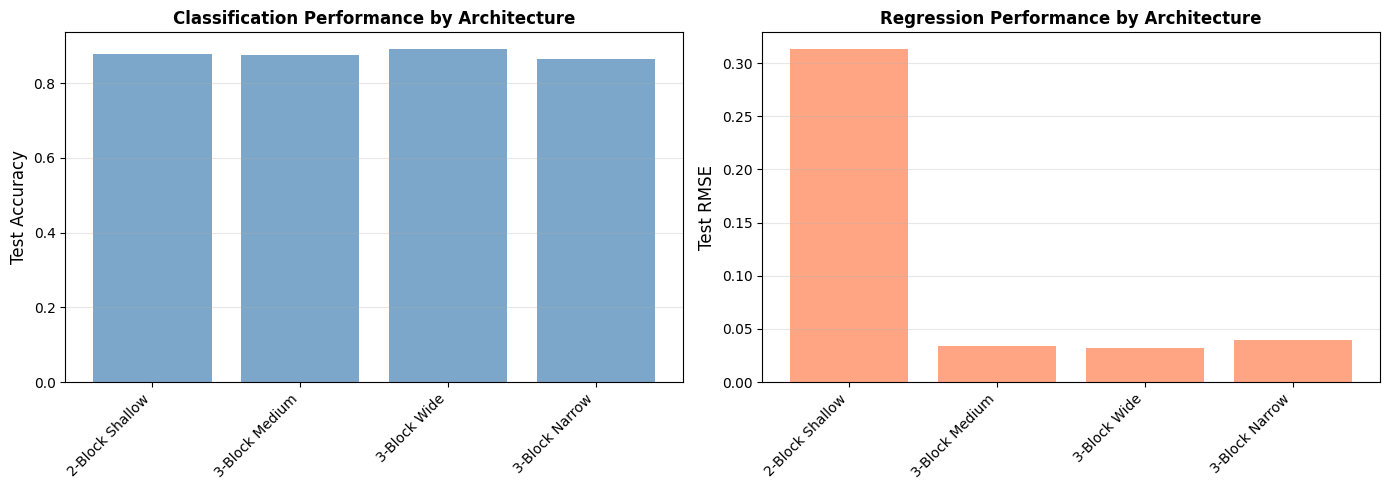

In [ ]:
# Experiment 5 - Network Architecture Exploration
"""
Explore different network architectures:
- Number of convolutional blocks
- Channel sizes
"""

arch_configs = [
    {'num_conv_blocks': 2, 'channels': [32, 64], 'name': '2-Block Shallow'},
    {'num_conv_blocks': 3, 'channels': [32, 64, 128], 'name': '3-Block Medium'},
    {'num_conv_blocks': 3, 'channels': [64, 128, 256], 'name': '3-Block Wide'},
    {'num_conv_blocks': 3, 'channels': [16, 32, 64], 'name': '3-Block Narrow'},
]

arch_results = []

print("\n" + "="*80)
print("EXPERIMENT 5: NETWORK ARCHITECTURE EXPLORATION")
print("="*80)

for arch_config in arch_configs:
    config = {**base_config,
              'lambda1': 1.0, 'lambda2': 1.0,
              'num_conv_blocks': arch_config['num_conv_blocks'],
              'channels': arch_config['channels'],
              'run_name': f"Architecture_{arch_config['name']}"}
    
    trainer, metrics = run_experiment(config, train_dataset, val_dataset, test_dataset)
    arch_results.append({
        'name': arch_config['name'],
        'num_blocks': arch_config['num_conv_blocks'],
        'channels': arch_config['channels'],
        'trainer': trainer,
        'metrics': metrics
    })

print("\n" + "="*80)
print("ARCHITECTURE EXPLORATION RESULTS")
print("="*80)
print(f"{'Architecture':<30} {'Test Acc':<12} {'Test RMSE':<12}")
print("-"*80)
for result in arch_results:
    print(f"{result['name']:<30} "
          f"{result['metrics']['test_accuracy']:<12.4f} "
          f"{result['metrics']['test_rmse']:<12.4f}")
print("="*80 + "\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

names = [r['name'] for r in arch_results]
accuracies = [r['metrics']['test_accuracy'] for r in arch_results]
rmses = [r['metrics']['test_rmse'] for r in arch_results]

axes[0].bar(range(len(names)), accuracies, color='steelblue', alpha=0.7)
axes[0].set_xticks(range(len(names)))
axes[0].set_xticklabels(names, rotation=45, ha='right')
axes[0].set_ylabel('Test Accuracy', fontsize=12)
axes[0].set_title('Classification Performance by Architecture', fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(range(len(names)), rmses, color='coral', alpha=0.7)
axes[1].set_xticks(range(len(names)))
axes[1].set_xticklabels(names, rotation=45, ha='right')
axes[1].set_ylabel('Test RMSE', fontsize=12)
axes[1].set_title('Regression Performance by Architecture', fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
save_path = 'plots/architecture_comparison.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved plot: {save_path}")

# Log to wandb
wandb.init(project="SMAI_A4_Q1_MultiTask_re_run", name="Architecture_Comparison_Plot", reinit=True)
wandb.log({"architecture_comparison": wandb.Image(fig)})
wandb.finish()

plt.show()



EXPERIMENT 6: BATCH SIZE EXPLORATION



BatchSize_Batch 32 (Small)
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8313, Val RMSE: 0.0359
Epoch 2/5 | Val Acc: 0.8590, Val RMSE: 0.0372
Epoch 3/5 | Val Acc: 0.8782, Val RMSE: 0.0402
Epoch 4/5 | Val Acc: 0.8767, Val RMSE: 0.0345
Epoch 5/5 | Val Acc: 0.8855, Val RMSE: 0.0327
Best Val Acc: 0.8855, Best Val RMSE: 0.0327

TEST RESULTS: Acc=0.8853, MAE=0.0246, RMSE=0.0326


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▄▂▁▁
train/mse_loss,█▂▂▂▁
train/total_loss,█▄▂▁▁
val/accuracy,▁▅▇▇█
val/ce_loss,█▅▂▂▁
val/mae,▄▅█▂▁
val/mse_loss,▄▅█▃▁



BatchSize_Batch 64 (Medium-Small)
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8363, Val RMSE: 0.0323
Epoch 2/5 | Val Acc: 0.8622, Val RMSE: 0.0340
Epoch 3/5 | Val Acc: 0.8748, Val RMSE: 0.0313
Epoch 4/5 | Val Acc: 0.8750, Val RMSE: 0.0329
Epoch 5/5 | Val Acc: 0.8777, Val RMSE: 0.0316
Best Val Acc: 0.8777, Best Val RMSE: 0.0313

TEST RESULTS: Acc=0.8756, MAE=0.0243, RMSE=0.0311


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▄▂▂▁
train/mse_loss,█▃▂▁▁
train/total_loss,█▄▂▂▁
val/accuracy,▁▅███
val/ce_loss,█▄▂▂▁
val/mae,▃█▁█▄
val/mse_loss,▄█▁▅▂



BatchSize_Batch 128 (Medium)
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8268, Val RMSE: 0.0381
Epoch 2/5 | Val Acc: 0.8468, Val RMSE: 0.0355
Epoch 3/5 | Val Acc: 0.8728, Val RMSE: 0.0346
Epoch 4/5 | Val Acc: 0.8690, Val RMSE: 0.0391
Epoch 5/5 | Val Acc: 0.8787, Val RMSE: 0.0350
Best Val Acc: 0.8787, Best Val RMSE: 0.0346

TEST RESULTS: Acc=0.8779, MAE=0.0261, RMSE=0.0346


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,█▂▂▁▁
train/total_loss,█▃▂▁▁
val/accuracy,▁▄▇▇█
val/ce_loss,█▆▂▂▁
val/mae,█▂▁▆▃
val/mse_loss,▆▂▁█▂



BatchSize_Batch 256 (Large)
Training for 5 epochs | λ1=1.0, λ2=1.0
Epoch 1/5 | Val Acc: 0.8167, Val RMSE: 0.0382
Epoch 2/5 | Val Acc: 0.8463, Val RMSE: 0.0468
Epoch 3/5 | Val Acc: 0.8592, Val RMSE: 0.0361
Epoch 4/5 | Val Acc: 0.8712, Val RMSE: 0.0367
Epoch 5/5 | Val Acc: 0.8813, Val RMSE: 0.0417
Best Val Acc: 0.8813, Best Val RMSE: 0.0361

TEST RESULTS: Acc=0.8806, MAE=0.0314, RMSE=0.0425


epoch,▁▃▅▆█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▃▂▁▁
train/mse_loss,█▂▁▁▁
train/total_loss,█▃▂▁▁
val/accuracy,▁▄▆▇█
val/ce_loss,█▅▃▂▁
val/mae,▃█▁▁▄
val/mse_loss,▂█▁▁▄



BATCH SIZE EXPLORATION RESULTS
Configuration                  Batch Size   Test Acc     Test RMSE   
--------------------------------------------------------------------------------
Batch 32 (Small)               32           0.8853       0.0326      
Batch 64 (Medium-Small)        64           0.8756       0.0311      
Batch 128 (Medium)             128          0.8779       0.0346      
Batch 256 (Large)              256          0.8806       0.0425      

Saved plot: plots/batch_size_comparison.png


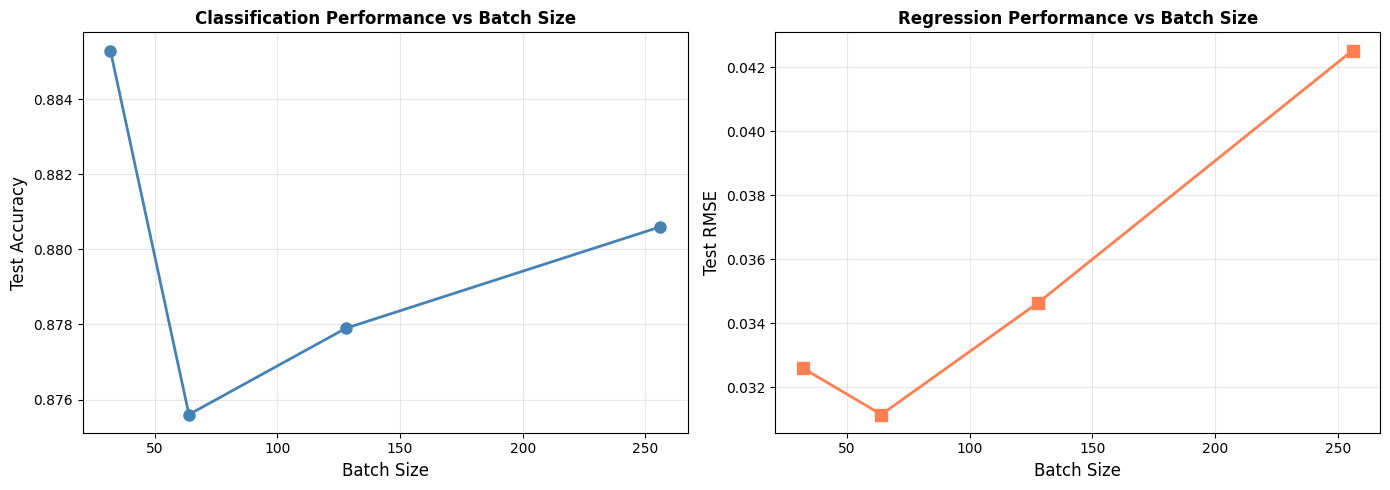

In [ ]:
# Experiment 6 - Batch Size Exploration
"""
Explore different batch sizes.
"""

batch_configs = [
    {'batch_size': 32, 'name': 'Batch 32 (Small)'},
    {'batch_size': 64, 'name': 'Batch 64 (Medium-Small)'},
    {'batch_size': 128, 'name': 'Batch 128 (Medium)'},
    {'batch_size': 256, 'name': 'Batch 256 (Large)'},
]

batch_results = []

print("\n" + "="*80)
print("EXPERIMENT 6: BATCH SIZE EXPLORATION")
print("="*80)

for batch_config in batch_configs:
    config = {**base_config,
              'lambda1': 1.0, 'lambda2': 1.0,
              'batch_size': batch_config['batch_size'],
              'run_name': f"BatchSize_{batch_config['name']}"}
    
    trainer, metrics = run_experiment(config, train_dataset, val_dataset, test_dataset)
    batch_results.append({
        'name': batch_config['name'],
        'batch_size': batch_config['batch_size'],
        'trainer': trainer,
        'metrics': metrics
    })

# Print Batch Size Comparison
print("\n" + "="*80)
print("BATCH SIZE EXPLORATION RESULTS")
print("="*80)
print(f"{'Configuration':<30} {'Batch Size':<12} {'Test Acc':<12} {'Test RMSE':<12}")
print("-"*80)
for result in batch_results:
    print(f"{result['name']:<30} {result['batch_size']:<12} "
          f"{result['metrics']['test_accuracy']:<12.4f} "
          f"{result['metrics']['test_rmse']:<12.4f}")
print("="*80 + "\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

batch_sizes = [r['batch_size'] for r in batch_results]
accuracies = [r['metrics']['test_accuracy'] for r in batch_results]
rmses = [r['metrics']['test_rmse'] for r in batch_results]

axes[0].plot(batch_sizes, accuracies, 'o-', color='steelblue', linewidth=2, markersize=8)
axes[0].set_xlabel('Batch Size', fontsize=12)
axes[0].set_ylabel('Test Accuracy', fontsize=12)
axes[0].set_title('Classification Performance vs Batch Size', fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(batch_sizes, rmses, 's-', color='coral', linewidth=2, markersize=8)
axes[1].set_xlabel('Batch Size', fontsize=12)
axes[1].set_ylabel('Test RMSE', fontsize=12)
axes[1].set_title('Regression Performance vs Batch Size', fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
save_path = 'plots/batch_size_comparison.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved plot: {save_path}")

wandb.init(project="SMAI_A4_Q1_MultiTask_re_run", name="BatchSize_Comparison_Plot", reinit=True)
wandb.log({"batch_size_comparison": wandb.Image(fig)})
wandb.finish()

plt.show()


COMBINED HYPERPARAMETER SEARCH
   1. Combined_Best_Overall
      λ1=1.0, λ2=1.0, LR=0.0005, Dropout=0.1, Opt=AdamW, Batch=128
   2. Combined_Max_Classification
      λ1=2.0, λ2=1.0, LR=0.0005, Dropout=0.1, Opt=AdamW, Batch=128
   3. Combined_Max_Regression
      λ1=1.0, λ2=2.0, LR=0.0005, Dropout=0.1, Opt=AdamW, Batch=32
   4. Combined_Balanced_Fast
      λ1=1.0, λ2=1.0, LR=0.001, Dropout=0.1, Opt=Adam, Batch=32
   5. Combined_Wide_Aggressive
      λ1=1.5, λ2=1.0, LR=0.0005, Dropout=0.1, Opt=AdamW, Batch=64

--------------------------------------------------------------------------------



Combined_Best_Overall
Training for 10 epochs | λ1=1.0, λ2=1.0
Epoch 1/10 | Val Acc: 0.8663, Val RMSE: 0.0280
Epoch 2/10 | Val Acc: 0.8855, Val RMSE: 0.0279
Epoch 3/10 | Val Acc: 0.8858, Val RMSE: 0.0280
Epoch 4/10 | Val Acc: 0.8948, Val RMSE: 0.0257
Epoch 5/10 | Val Acc: 0.8992, Val RMSE: 0.0229
Epoch 6/10 | Val Acc: 0.8995, Val RMSE: 0.0238
Epoch 7/10 | Val Acc: 0.9048, Val RMSE: 0.0234
Epoch 8/10 | Val Acc: 0.9087, Val RMSE: 0.0228
Epoch 9/10 | Val Acc: 0.9122, Val RMSE: 0.0238
Epoch 10/10 | Val Acc: 0.9135, Val RMSE: 0.0228
Best Val Acc: 0.9135, Best Val RMSE: 0.0228

TEST RESULTS: Acc=0.9132, MAE=0.0163, RMSE=0.0226


epoch,▁▂▃▃▄▅▆▆▇█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▄▃▂▂▂▂▁▁▁
train/mse_loss,█▂▂▂▁▁▁▁▁▁
train/total_loss,█▄▃▂▂▂▂▁▁▁
val/accuracy,▁▄▄▅▆▆▇▇██
val/ce_loss,█▅▅▄▃▃▂▂▁▁
val/mae,▆▇█▄▁▂▂▁▂▂
val/mse_loss,███▅▁▂▂▁▂▁



Combined_Max_Classification
Training for 10 epochs | λ1=2.0, λ2=1.0
Epoch 1/10 | Val Acc: 0.8553, Val RMSE: 0.0261
Epoch 2/10 | Val Acc: 0.8850, Val RMSE: 0.0207
Epoch 3/10 | Val Acc: 0.8815, Val RMSE: 0.0211
Epoch 4/10 | Val Acc: 0.8898, Val RMSE: 0.0220
Epoch 5/10 | Val Acc: 0.9032, Val RMSE: 0.0213
Epoch 6/10 | Val Acc: 0.8965, Val RMSE: 0.0241
Epoch 7/10 | Val Acc: 0.9107, Val RMSE: 0.0184
Epoch 8/10 | Val Acc: 0.9105, Val RMSE: 0.0181
Epoch 9/10 | Val Acc: 0.9123, Val RMSE: 0.0200
Epoch 10/10 | Val Acc: 0.9058, Val RMSE: 0.0198
Best Val Acc: 0.9123, Best Val RMSE: 0.0181

TEST RESULTS: Acc=0.9124, MAE=0.0155, RMSE=0.0200


epoch,▁▂▃▃▄▅▆▆▇█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▄▃▃▂▂▂▁▁▁
train/mse_loss,█▂▂▁▁▁▁▁▁▁
train/total_loss,█▄▃▃▂▂▂▁▁▁
val/accuracy,▁▅▄▅▇▆███▇
val/ce_loss,█▄▅▄▂▃▁▁▁▂
val/mae,█▃▄▅▄▇▁▁▃▃
val/mse_loss,█▃▃▄▃▆▁▁▂▂


...


Combined_Balanced_Fast
Training for 10 epochs | λ1=1.0, λ2=1.0
Epoch 1/10 | Val Acc: 0.8588, Val RMSE: 0.0305
Epoch 2/10 | Val Acc: 0.8842, Val RMSE: 0.0312
Epoch 3/10 | Val Acc: 0.8930, Val RMSE: 0.0260
Epoch 4/10 | Val Acc: 0.8843, Val RMSE: 0.0220
Epoch 5/10 | Val Acc: 0.9033, Val RMSE: 0.0231
Epoch 6/10 | Val Acc: 0.8878, Val RMSE: 0.0193
Epoch 7/10 | Val Acc: 0.9143, Val RMSE: 0.0190
Epoch 8/10 | Val Acc: 0.9135, Val RMSE: 0.0207
Epoch 9/10 | Val Acc: 0.9195, Val RMSE: 0.0201
Epoch 10/10 | Val Acc: 0.9170, Val RMSE: 0.0194
Best Val Acc: 0.9195, Best Val RMSE: 0.0190

TEST RESULTS: Acc=0.9157, MAE=0.0157, RMSE=0.0202


epoch,▁▂▃▃▄▅▆▆▇█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▄▃▃▂▂▂▁▁▁
train/mse_loss,█▁▁▁▁▁▁▁▁▁
train/total_loss,█▄▃▂▂▂▂▁▁▁
val/accuracy,▁▄▅▄▆▄▇▇██
val/ce_loss,█▅▄▄▃▅▂▂▁▁
val/mae,██▅▃▄▁▁▂▂▁
val/mse_loss,██▅▂▃▁▁▂▂▁



Combined_Wide_Aggressive
Training for 10 epochs | λ1=1.5, λ2=1.0
Epoch 1/10 | Val Acc: 0.8708, Val RMSE: 0.0305
Epoch 2/10 | Val Acc: 0.8730, Val RMSE: 0.0355
Epoch 3/10 | Val Acc: 0.8843, Val RMSE: 0.0219
Epoch 4/10 | Val Acc: 0.8982, Val RMSE: 0.0182
Epoch 5/10 | Val Acc: 0.8995, Val RMSE: 0.0200
Epoch 6/10 | Val Acc: 0.9025, Val RMSE: 0.0202
Epoch 7/10 | Val Acc: 0.9088, Val RMSE: 0.0225
Epoch 8/10 | Val Acc: 0.9128, Val RMSE: 0.0203
Epoch 9/10 | Val Acc: 0.9135, Val RMSE: 0.0204
Epoch 10/10 | Val Acc: 0.9163, Val RMSE: 0.0185
Best Val Acc: 0.9163, Best Val RMSE: 0.0182

TEST RESULTS: Acc=0.9166, MAE=0.0140, RMSE=0.0183


epoch,▁▂▃▃▄▅▆▆▇█
test/accuracy,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▄▃▃▂▂▂▁▁▁
train/mse_loss,█▃▂▂▂▂▁▁▁▁
train/total_loss,█▄▃▃▂▂▂▁▁▁
val/accuracy,▁▁▃▅▅▆▇▇██
val/ce_loss,██▆▃▄▂▂▂▁▁
val/mae,▆█▂▁▂▂▃▂▂▁
val/mse_loss,▅█▂▁▂▂▂▂▂▁



COMBINED HYPERPARAMETER SEARCH RESULTS
Configuration                            Test Acc     Test RMSE    Test MAE    
--------------------------------------------------------------------------------
Combined_Best_Overall                    0.9132       0.0226       0.0163      
Combined_Max_Classification              0.9124       0.0200       0.0155      
Combined_Max_Regression                  0.9116       0.0195       0.0149      
Combined_Balanced_Fast                   0.9157       0.0202       0.0157      
Combined_Wide_Aggressive                 0.9166       0.0183       0.0140      

 BEST COMBINED CONFIG (Accuracy): Combined_Wide_Aggressive
   Accuracy: 0.9166
   RMSE: 0.0183

 BEST COMBINED CONFIG (RMSE): Combined_Wide_Aggressive
   Accuracy: 0.9166
   RMSE: 0.0183

📊 COMPARISON WITH PHASE 1:
   Phase 1 Best Accuracy: 0.9167 (Dropout 0.1)
     Combined matched/close to Phase 1 best
   Phase 1 Best RMSE: 0.0237 (Dropout 0.1)
    Combined search IMPROVED! (-0.0054)

Saved pl

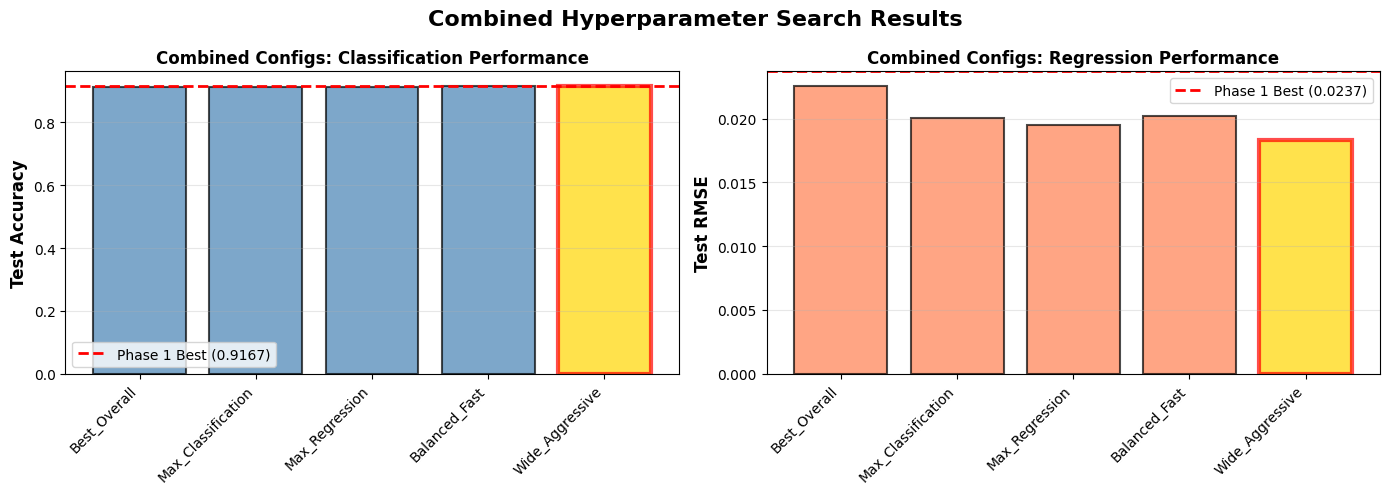

In [ ]:
# Combined Hyperparameter Search (Best Configurations)

print("\n" + "="*80)
print("COMBINED HYPERPARAMETER SEARCH")
print("="*80)

combined_configs = [
    # Config 1
    {
        'lambda1': 1.0,
        'lambda2': 1.0,
        'lr': 0.0005,        
        'batch_size': 128,   
        'num_conv_blocks': 3,
        'channels': [64, 128, 256],
        'dropout': 0.1,      
        'optimizer': 'AdamW', 
        'epochs': 10,
        'run_name': 'Combined_Best_Overall'
    },
    
    # Config 2: Maximum Classification Focus
    {
        'lambda1': 2.0,      # Best for accuracy
        'lambda2': 1.0,
        'lr': 0.0005,
        'batch_size': 128,
        'num_conv_blocks': 3,
        'channels': [64, 128, 256],  # Wide arch for classification
        'dropout': 0.1,      # Low dropout for accuracy
        'optimizer': 'AdamW',
        'epochs': 10,
        'run_name': 'Combined_Max_Classification'
    },
    
    # Config 3: Maximum Regression Focus
    {
        'lambda1': 1.0,
        'lambda2': 2.0,      # Best for RMSE
        'lr': 0.0005,        # Stable LR
        'batch_size': 32,    # Small batch for regression
        'num_conv_blocks': 3,
        'channels': [32, 64, 128],  # Medium arch
        'dropout': 0.1,      # Low dropout
        'optimizer': 'AdamW',
        'epochs': 10,
        'run_name': 'Combined_Max_Regression'
    },
    
    # Config 4: Balanced High Performance
    {
        'lambda1': 1.0,
        'lambda2': 1.0,
        'lr': 0.001,         # Medium LR for faster convergence
        'batch_size': 32,    # Small batch for generalization
        'num_conv_blocks': 3,
        'channels': [64, 128, 256],  # Wide arch
        'dropout': 0.1,      # Best dropout
        'optimizer': 'Adam',  # Fast convergence
        'epochs': 10,
        'run_name': 'Combined_Balanced_Fast'
    },
    
    # Config 5: Aggressive Wide Network (Test limits)
    {
        'lambda1': 1.5,      # Slightly favor classification
        'lambda2': 1.0,
        'lr': 0.0005,
        'batch_size': 64,    # Medium batch
        'num_conv_blocks': 3,
        'channels': [64, 128, 256],  # Wide
        'dropout': 0.1,      # Low dropout to leverage capacity
        'optimizer': 'AdamW',
        'epochs': 10,
        'run_name': 'Combined_Wide_Aggressive'
    },
]

for i, config in enumerate(combined_configs, 1):
    print(f"   {i}. {config['run_name']}")
    print(f"      λ1={config['lambda1']}, λ2={config['lambda2']}, "
          f"LR={config['lr']}, Dropout={config['dropout']}, "
          f"Opt={config['optimizer']}, Batch={config['batch_size']}")

print("\n" + "-"*80)

combined_results = []

for config in combined_configs:
    trainer, metrics = run_experiment(config, train_dataset, val_dataset, test_dataset)
    combined_results.append({
        'name': config['run_name'],
        'config': config,
        'trainer': trainer,
        'metrics': metrics
    })

# Print Combined Results
print("\n" + "="*80)
print("COMBINED HYPERPARAMETER SEARCH RESULTS")
print("="*80)
print(f"{'Configuration':<40} {'Test Acc':<12} {'Test RMSE':<12} {'Test MAE':<12}")
print("-"*80)
for result in combined_results:
    print(f"{result['name']:<40} "
          f"{result['metrics']['test_accuracy']:<12.4f} "
          f"{result['metrics']['test_rmse']:<12.4f} "
          f"{result['metrics']['test_mae']:<12.4f}")
print("="*80)

best_combined_acc = max(combined_results, key=lambda x: x['metrics']['test_accuracy'])
best_combined_rmse = min(combined_results, key=lambda x: x['metrics']['test_rmse'])

print(f"\n BEST COMBINED CONFIG (Accuracy): {best_combined_acc['name']}")
print(f"   Accuracy: {best_combined_acc['metrics']['test_accuracy']:.4f}")
print(f"   RMSE: {best_combined_acc['metrics']['test_rmse']:.4f}")

print(f"\n BEST COMBINED CONFIG (RMSE): {best_combined_rmse['name']}")
print(f"   Accuracy: {best_combined_rmse['metrics']['test_accuracy']:.4f}")
print(f"   RMSE: {best_combined_rmse['metrics']['test_rmse']:.4f}")

print(f"\n📊 COMPARISON WITH PHASE 1:")
print(f"   Phase 1 Best Accuracy: 0.9167 (Dropout 0.1)")
if best_combined_acc['metrics']['test_accuracy'] > 0.9167:
    print(f"    Combined search IMPROVED! (+{best_combined_acc['metrics']['test_accuracy'] - 0.9167:.4f})")
else:
    print(f"     Combined matched/close to Phase 1 best")

print(f"   Phase 1 Best RMSE: 0.0237 (Dropout 0.1)")
if best_combined_rmse['metrics']['test_rmse'] < 0.0237:
    print(f"    Combined search IMPROVED! (-{0.0237 - best_combined_rmse['metrics']['test_rmse']:.4f})")
else:
    print(f"     Combined matched/close to Phase 1 best")
print("="*80 + "\n")

# Plot Combined Results Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

names = [r['name'].replace('Combined_', '') for r in combined_results]
accuracies = [r['metrics']['test_accuracy'] for r in combined_results]
rmses = [r['metrics']['test_rmse'] for r in combined_results]

axes[0].bar(range(len(names)), accuracies, color='steelblue', alpha=0.7, edgecolor='black', linewidth=1.5)
axes[0].set_xticks(range(len(names)))
axes[0].set_xticklabels(names, rotation=45, ha='right')
axes[0].set_ylabel('Test Accuracy', fontsize=12, fontweight='bold')
axes[0].set_title('Combined Configs: Classification Performance', fontweight='bold')
axes[0].axhline(y=0.9167, color='red', linestyle='--', linewidth=2, label='Phase 1 Best (0.9167)')
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend()

best_idx = accuracies.index(max(accuracies))
axes[0].patches[best_idx].set_facecolor('gold')
axes[0].patches[best_idx].set_edgecolor('red')
axes[0].patches[best_idx].set_linewidth(3)

axes[1].bar(range(len(names)), rmses, color='coral', alpha=0.7, edgecolor='black', linewidth=1.5)
axes[1].set_xticks(range(len(names)))
axes[1].set_xticklabels(names, rotation=45, ha='right')
axes[1].set_ylabel('Test RMSE', fontsize=12, fontweight='bold')
axes[1].set_title('Combined Configs: Regression Performance', fontweight='bold')
axes[1].axhline(y=0.0237, color='red', linestyle='--', linewidth=2, label='Phase 1 Best (0.0237)')
axes[1].grid(axis='y', alpha=0.3)
axes[1].legend()

best_idx = rmses.index(min(rmses))
axes[1].patches[best_idx].set_facecolor('gold')
axes[1].patches[best_idx].set_edgecolor('red')
axes[1].patches[best_idx].set_linewidth(3)

plt.suptitle('Combined Hyperparameter Search Results', fontsize=16, fontweight='bold')
plt.tight_layout()

save_path = 'plots/combined_search_comparison.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved plot: {save_path}")


wandb.init(project="SMAI_A4_Q1_MultiTask_re_run", name="Combined_Search_Results", reinit=True)
wandb.log({"combined_search_comparison": wandb.Image(fig)})
wandb.finish()

plt.show()

In [ ]:
# Results Summary
"""
Aggregate all experiment results and identify best models.
Includes results from both isolated experiments AND combined search.
"""

all_results = []


for r in lambda_results:
    all_results.append({
        'experiment': 'Lambda Ratio',
        'config': r['name'],
        'accuracy': r['metrics']['test_accuracy'],
        'rmse': r['metrics']['test_rmse'],
        'mae': r['metrics']['test_mae'],
        'trainer': r['trainer'],
        'metrics': r['metrics']
    })

for r in lr_results:
    all_results.append({
        'experiment': 'Learning Rate',
        'config': r['name'],
        'accuracy': r['metrics']['test_accuracy'],
        'rmse': r['metrics']['test_rmse'],
        'mae': r['metrics']['test_mae'],
        'trainer': r['trainer'],
        'metrics': r['metrics']
    })

for r in dropout_results:
    all_results.append({
        'experiment': 'Dropout Rate',
        'config': r['name'],
        'accuracy': r['metrics']['test_accuracy'],
        'rmse': r['metrics']['test_rmse'],
        'mae': r['metrics']['test_mae'],
        'trainer': r['trainer'],
        'metrics': r['metrics']
    })

for r in optimizer_results:
    all_results.append({
        'experiment': 'Optimizer',
        'config': r['name'],
        'accuracy': r['metrics']['test_accuracy'],
        'rmse': r['metrics']['test_rmse'],
        'mae': r['metrics']['test_mae'],
        'trainer': r['trainer'],
        'metrics': r['metrics']
    })

for r in arch_results:
    all_results.append({
        'experiment': 'Architecture',
        'config': r['name'],
        'accuracy': r['metrics']['test_accuracy'],
        'rmse': r['metrics']['test_rmse'],
        'mae': r['metrics']['test_mae'],
        'trainer': r['trainer'],
        'metrics': r['metrics']
    })

for r in batch_results:
    all_results.append({
        'experiment': 'Batch Size',
        'config': r['name'],
        'accuracy': r['metrics']['test_accuracy'],
        'rmse': r['metrics']['test_rmse'],
        'mae': r['metrics']['test_mae'],
        'trainer': r['trainer'],
        'metrics': r['metrics']
    })

for r in combined_results:
    all_results.append({
        'experiment': 'Combined Search',
        'config': r['name'],
        'accuracy': r['metrics']['test_accuracy'],
        'rmse': r['metrics']['test_rmse'],
        'mae': r['metrics']['test_mae'],
        'trainer': r['trainer'],
        'metrics': r['metrics']
    })

best_acc_idx = np.argmax([r['accuracy'] for r in all_results])
best_rmse_idx = np.argmin([r['rmse'] for r in all_results])

best_acc_result = all_results[best_acc_idx]
best_rmse_result = all_results[best_rmse_idx]

print("\n" + "="*90)
print("COMPREHENSIVE EXPERIMENT RESULTS SUMMARY (ALL EXPERIMENTS)")
print("="*90)
print(f"{'Experiment':<20} {'Configuration':<35} {'Acc':<10} {'RMSE':<10} {'MAE':<10}")
print("-"*90)
for result in all_results:
    print(f"{result['experiment']:<20} {result['config']:<35} "
          f"{result['accuracy']:<10.4f} {result['rmse']:<10.4f} {result['mae']:<10.4f}")
print("="*90)


print(f"\nTotal Experiments: {len(all_results)}")
exp_counts = {}
for r in all_results:
    exp_counts[r['experiment']] = exp_counts.get(r['experiment'], 0) + 1
print("Breakdown:")
for exp_type, count in exp_counts.items():
    print(f"  - {exp_type}: {count} runs")

print("\n" + "="*90)
print("BEST MODELS IDENTIFIED (ACROSS ALL EXPERIMENTS)")
print("="*90)
print(f"\n BEST CLASSIFICATION MODEL:")
print(f"   Experiment Type: {best_acc_result['experiment']}")
print(f"   Configuration: {best_acc_result['config']}")
print(f"   Test Accuracy: {best_acc_result['accuracy']:.4f}")
print(f"   Test RMSE: {best_acc_result['rmse']:.4f}")
print(f"   Test MAE: {best_acc_result['mae']:.4f}")

print(f"\n BEST REGRESSION MODEL:")
print(f"   Experiment Type: {best_rmse_result['experiment']}")
print(f"   Configuration: {best_rmse_result['config']}")
print(f"   Test Accuracy: {best_rmse_result['accuracy']:.4f}")
print(f"   Test RMSE: {best_rmse_result['rmse']:.4f}")
print(f"   Test MAE: {best_rmse_result['mae']:.4f}")


COMPREHENSIVE EXPERIMENT RESULTS SUMMARY (ALL EXPERIMENTS)
Experiment           Configuration                       Acc        RMSE       MAE       
------------------------------------------------------------------------------------------
Lambda Ratio         Lambda 1:1 (Balanced)               0.8720     0.0351     0.0251    
Lambda Ratio         Lambda 2:1 (Class Focus)            0.8813     0.0318     0.0237    
Lambda Ratio         Lambda 1:2 (Regression Focus)       0.8741     0.0399     0.0299    
Learning Rate        LR 0.0001 (Very Low)                0.8391     0.0326     0.0249    
Learning Rate        LR 0.0005 (Low)                     0.8758     0.0311     0.0235    
Learning Rate        LR 0.001 (Medium)                   0.8820     0.0298     0.0219    
Learning Rate        LR 0.005 (High)                     0.8766     0.3132     0.2868    
Learning Rate        LR 0.01 (Very High)                 0.8592     0.3132     0.2868    
Dropout Rate         Dropout 0.1 (Low) 


CONFUSION MATRIX - BEST CLASSIFICATION MODEL


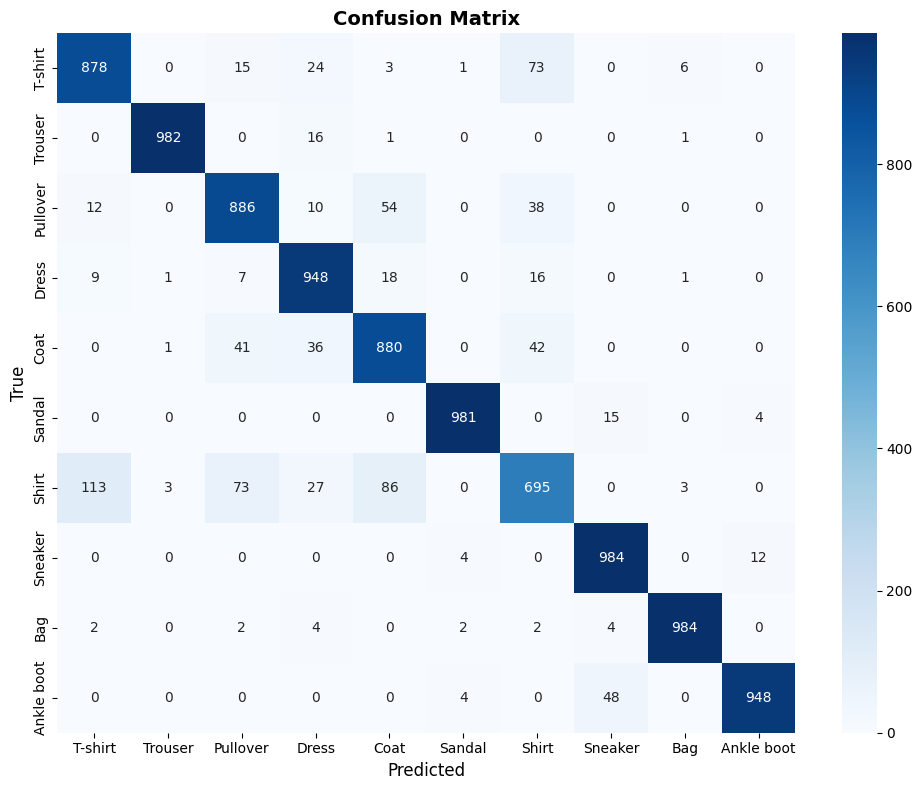

In [ ]:
# confusion Matrix for Best Classification Model
"""
Plot confusion matrix for the best performing classification model.
"""

print("\n" + "="*80)
print("CONFUSION MATRIX - BEST CLASSIFICATION MODEL")
print("="*80)

wandb.init(project="SMAI_A4_Q1_MultiTask_re_run", name="Best_Model_Confusion_Matrix", reinit=True)

plot_confusion_matrix(
    best_acc_result['metrics']['labels'],
    best_acc_result['metrics']['predictions'],
    save_path='plots/confusion_matrix_best_classification.png'
)

wandb.finish()


FEATURE MAP VISUALIZATION - BEST MODEL



--- Processing Test Image 1: Dress ---
Saved GRID view: plots/feature_maps_grid_img1.png


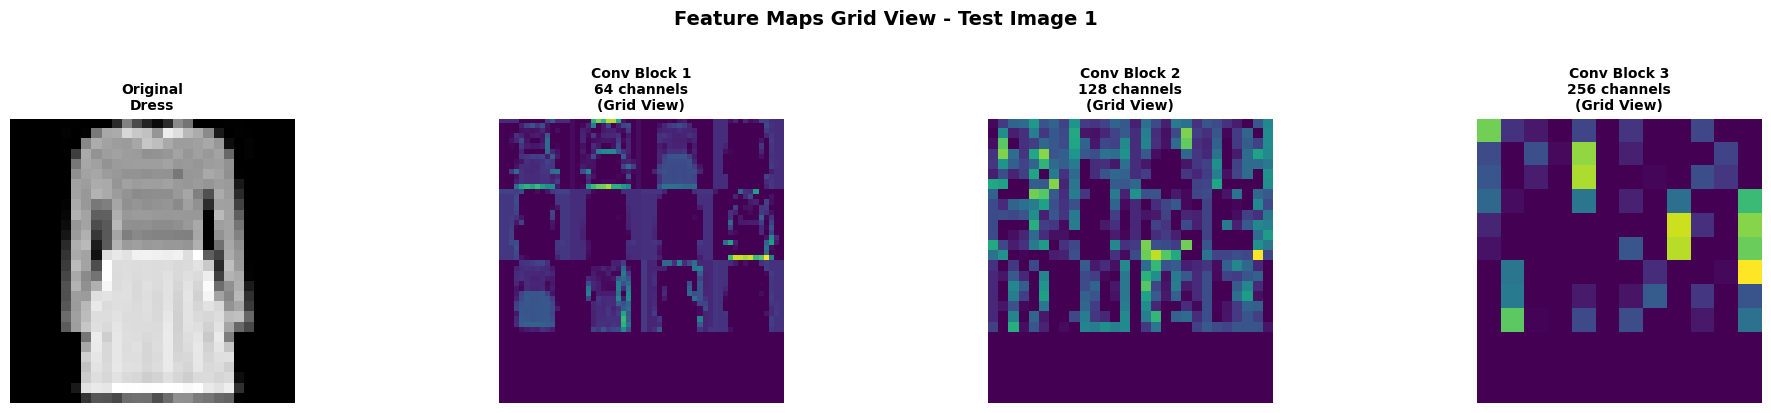

Saved INDIVIDUAL channels (Layer 1): plots/feature_maps_individual_img1_layer1.png


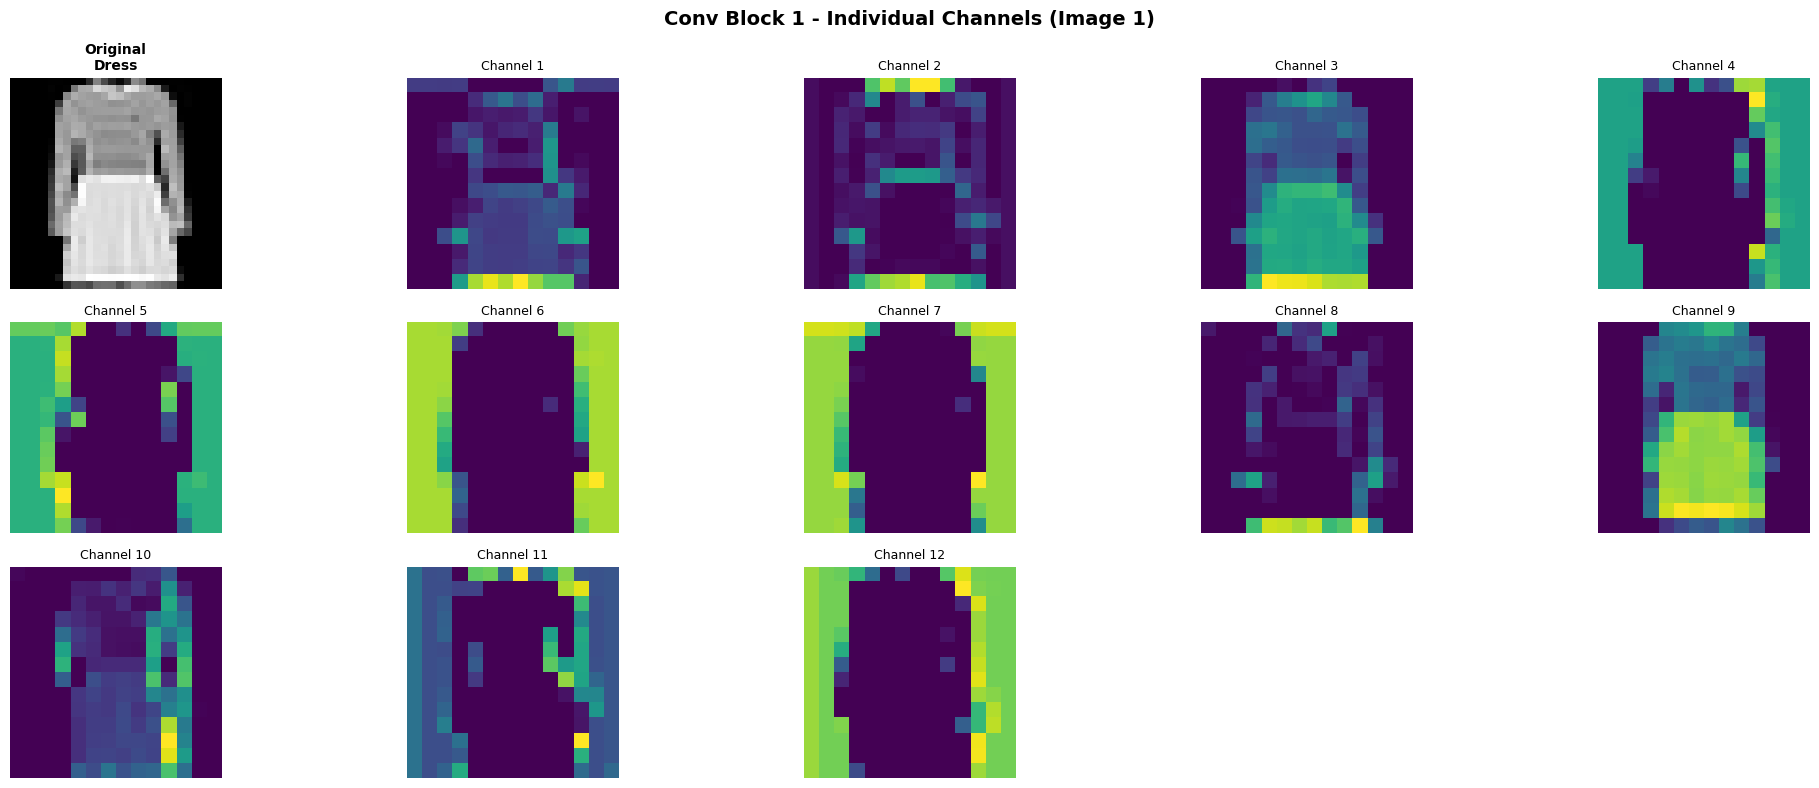

Saved INDIVIDUAL channels (Layer 2): plots/feature_maps_individual_img1_layer2.png


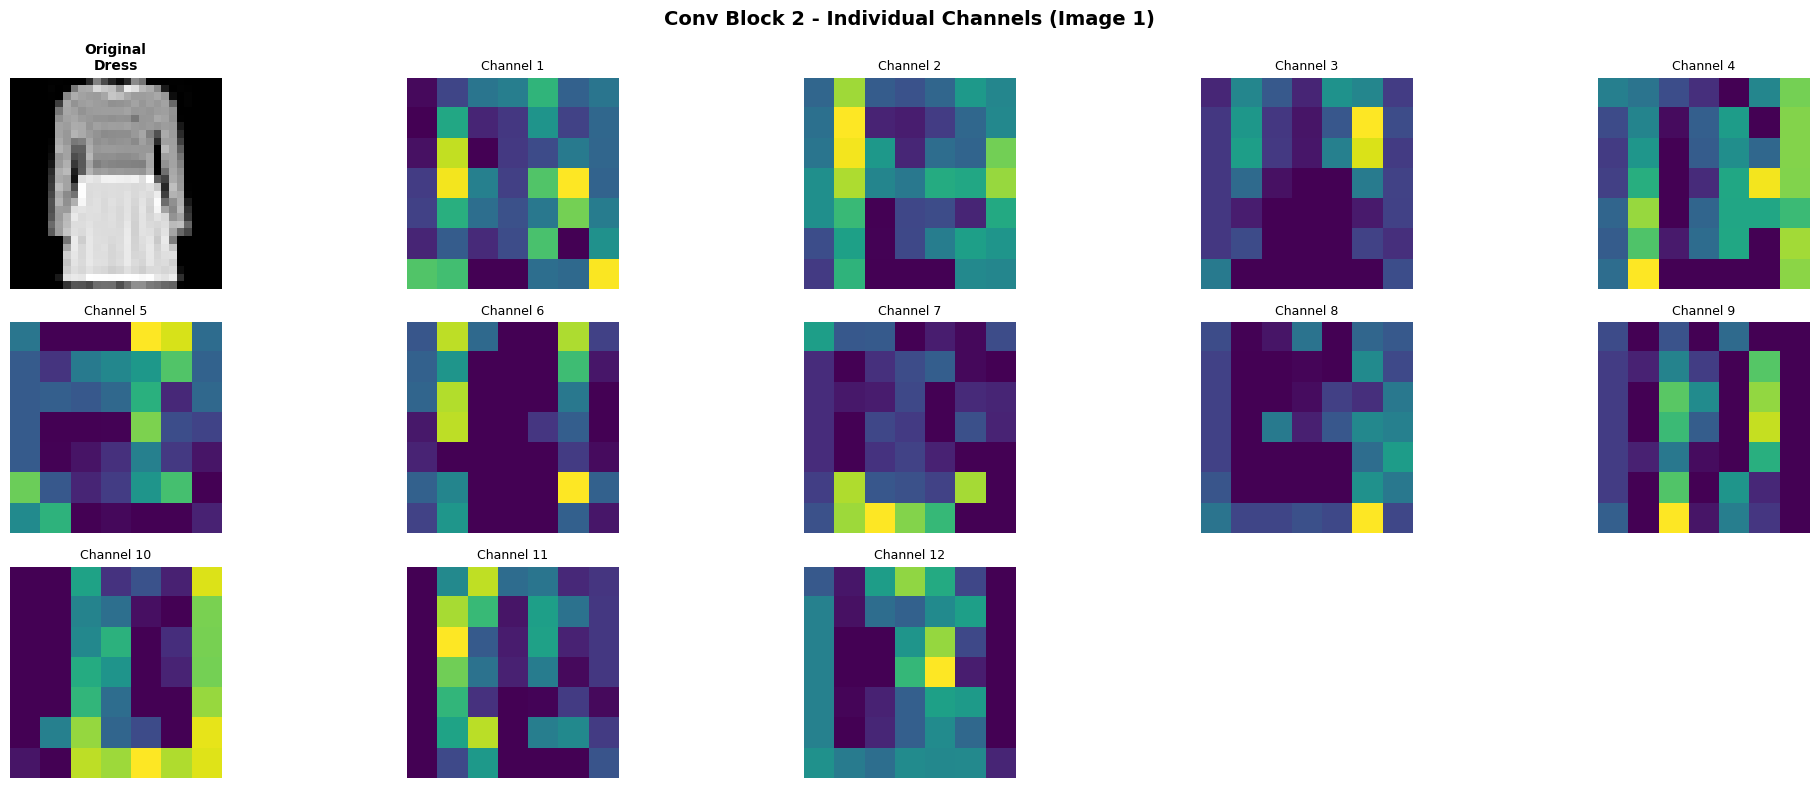

Saved INDIVIDUAL channels (Layer 3): plots/feature_maps_individual_img1_layer3.png


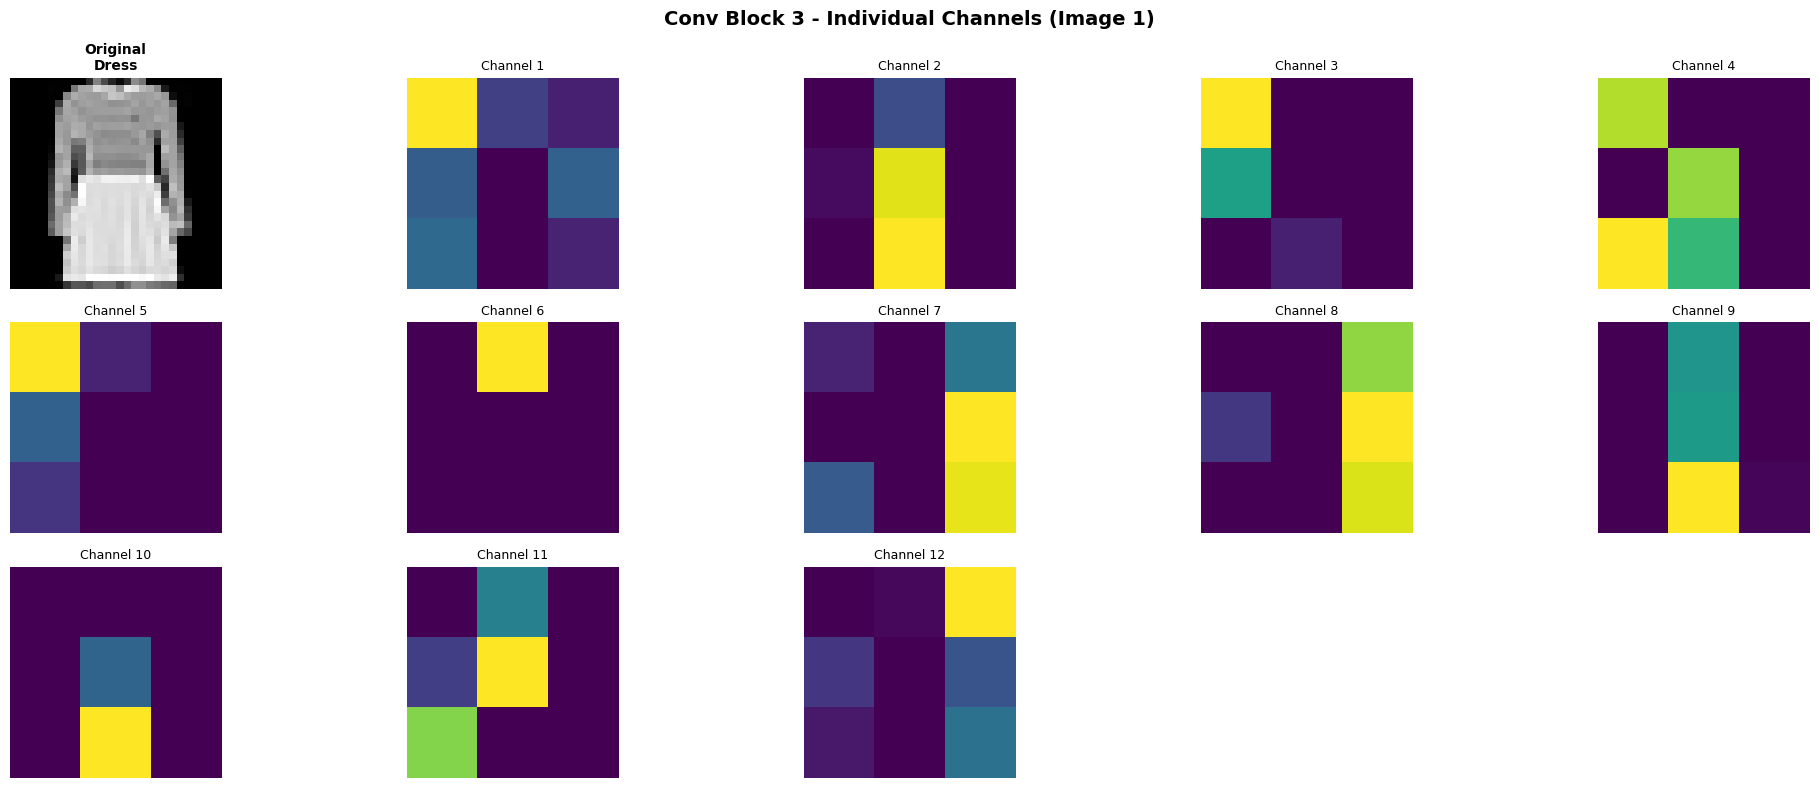

 Completed visualization for Image 1


--- Processing Test Image 2: Bag ---
Saved GRID view: plots/feature_maps_grid_img2.png


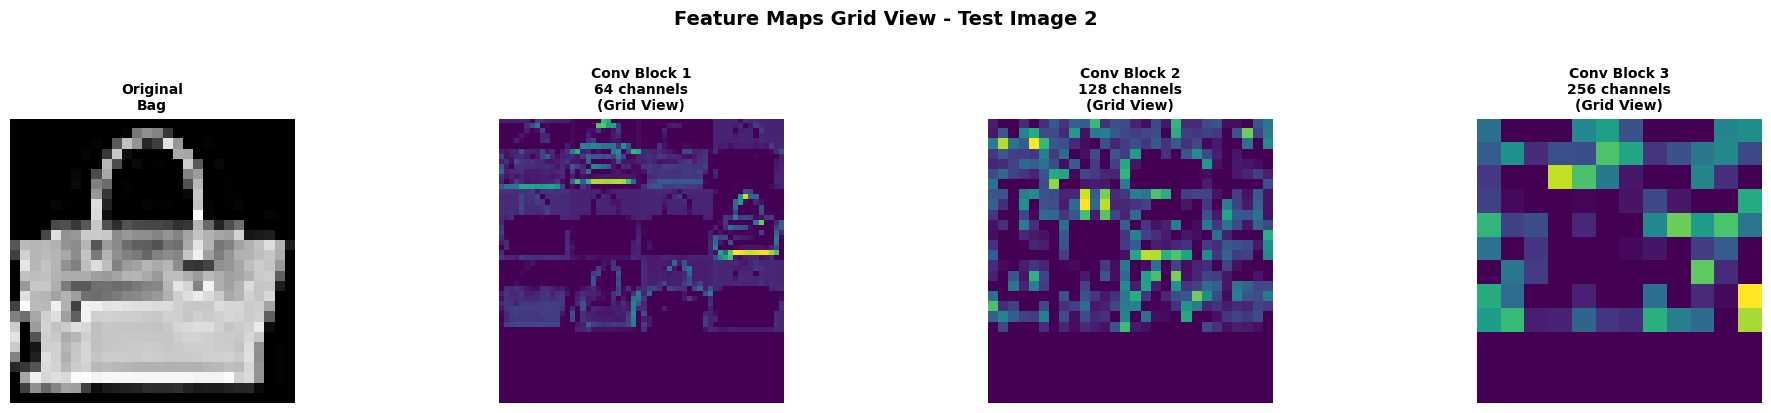

Saved INDIVIDUAL channels (Layer 1): plots/feature_maps_individual_img2_layer1.png


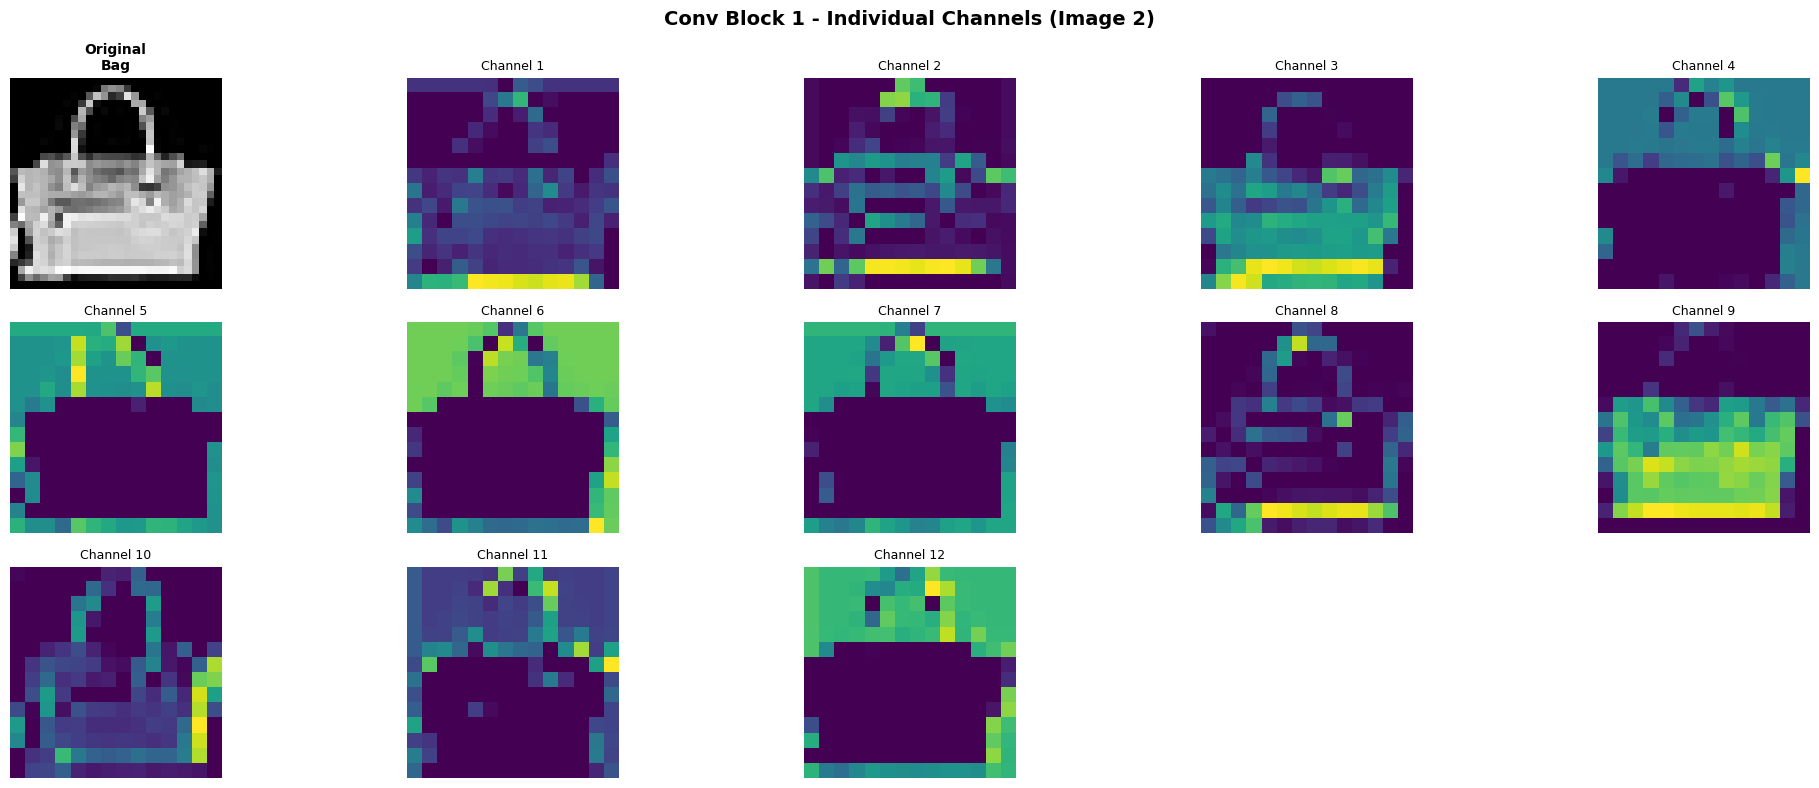

Saved INDIVIDUAL channels (Layer 2): plots/feature_maps_individual_img2_layer2.png


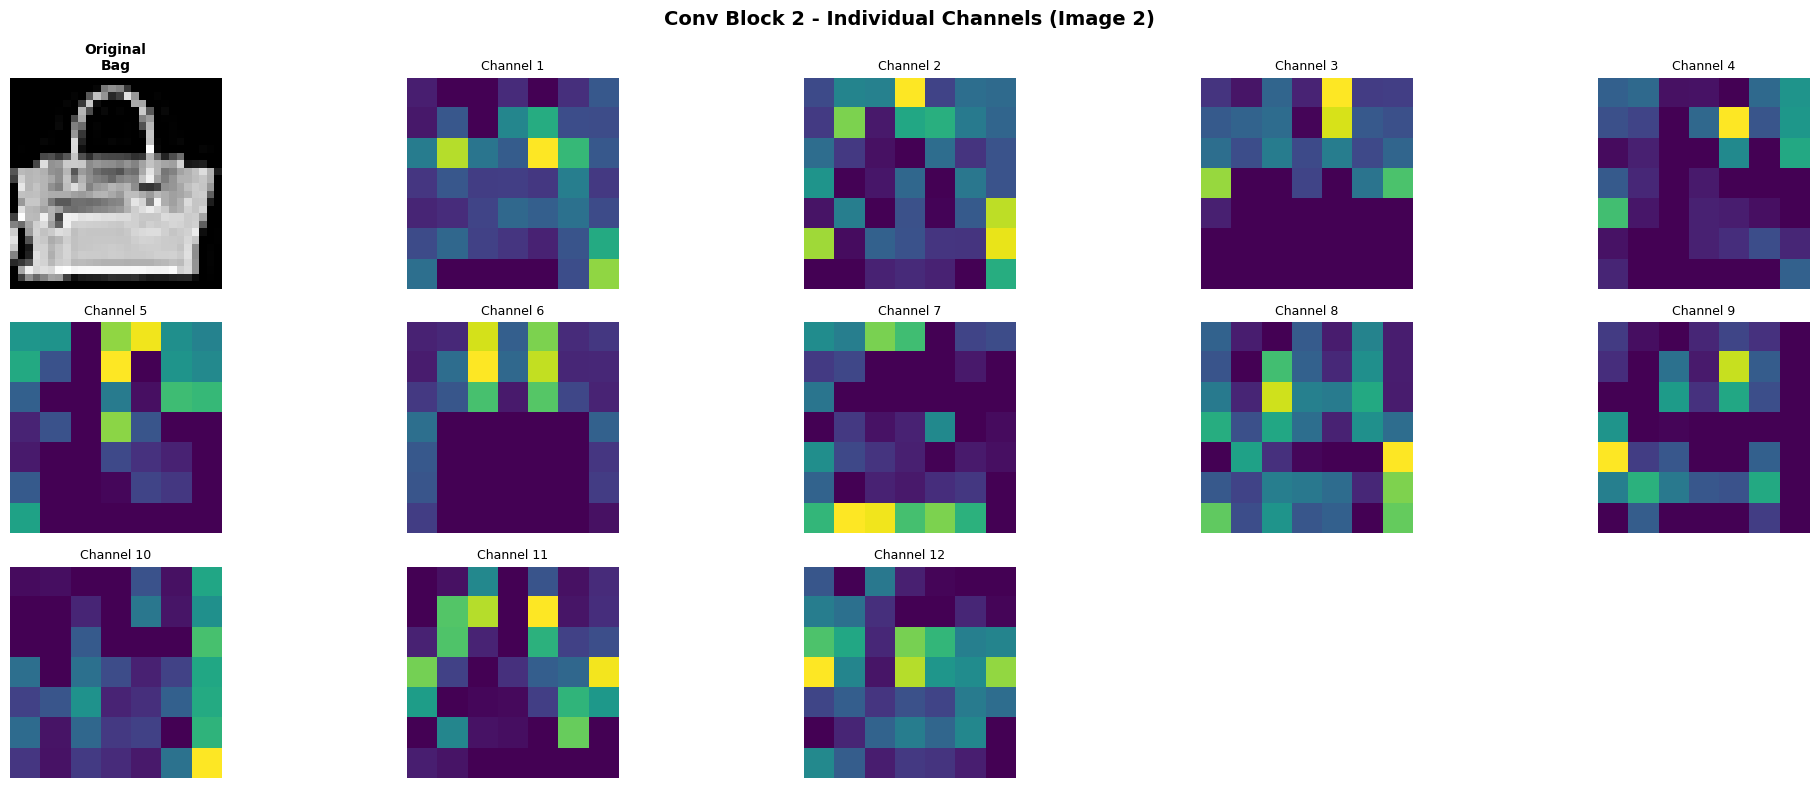

Saved INDIVIDUAL channels (Layer 3): plots/feature_maps_individual_img2_layer3.png


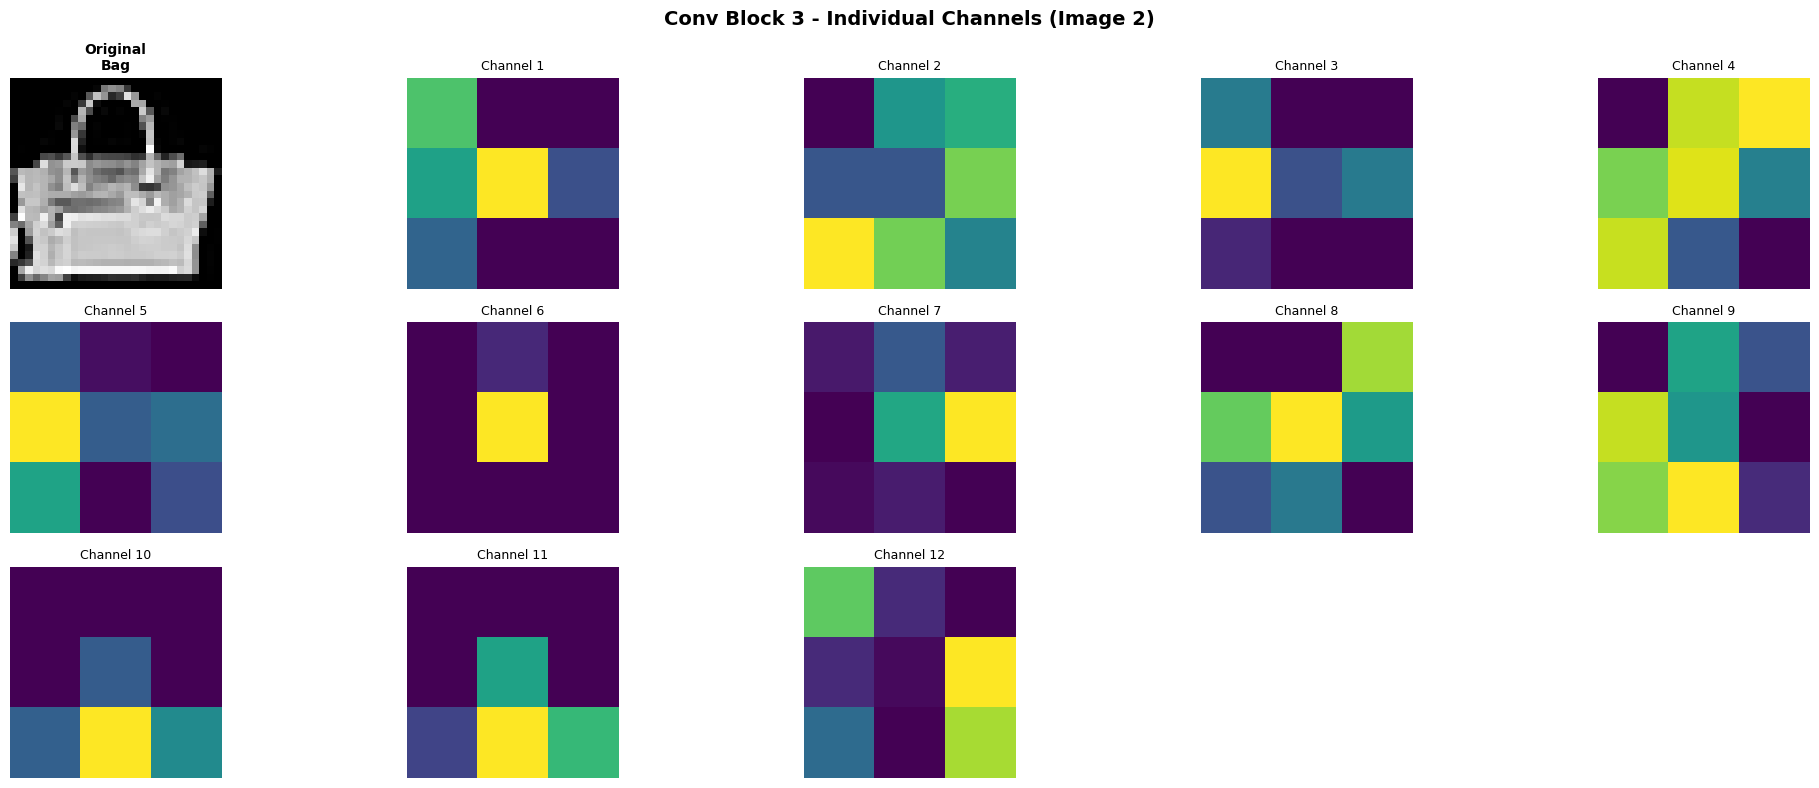

 Completed visualization for Image 2


--- Processing Test Image 3: Pullover ---
Saved GRID view: plots/feature_maps_grid_img3.png


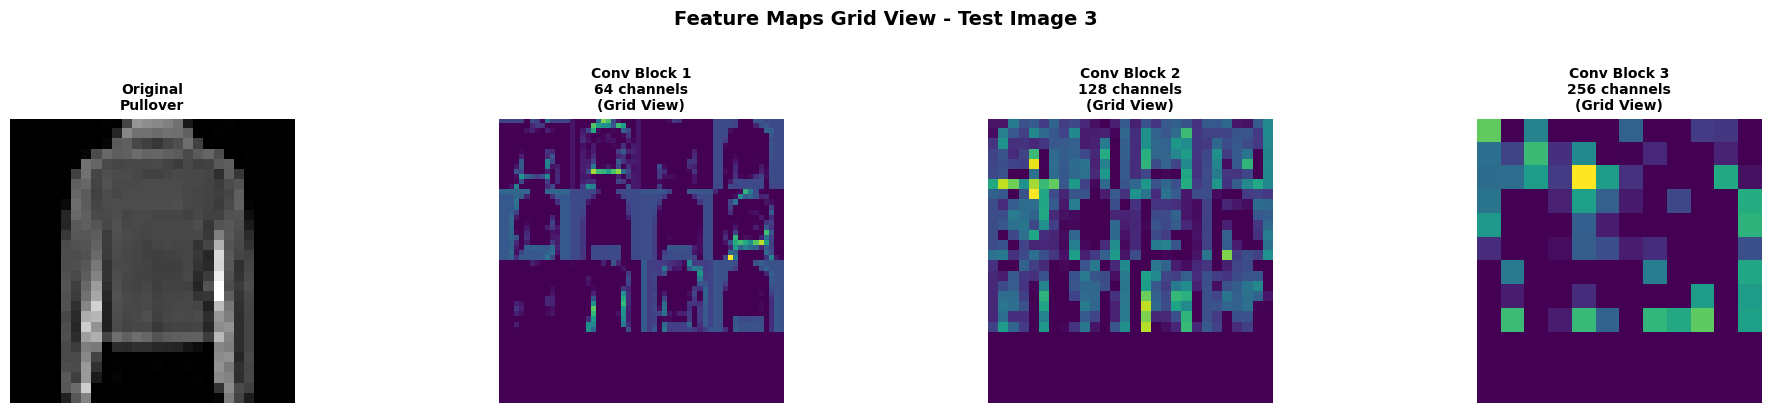

Saved INDIVIDUAL channels (Layer 1): plots/feature_maps_individual_img3_layer1.png


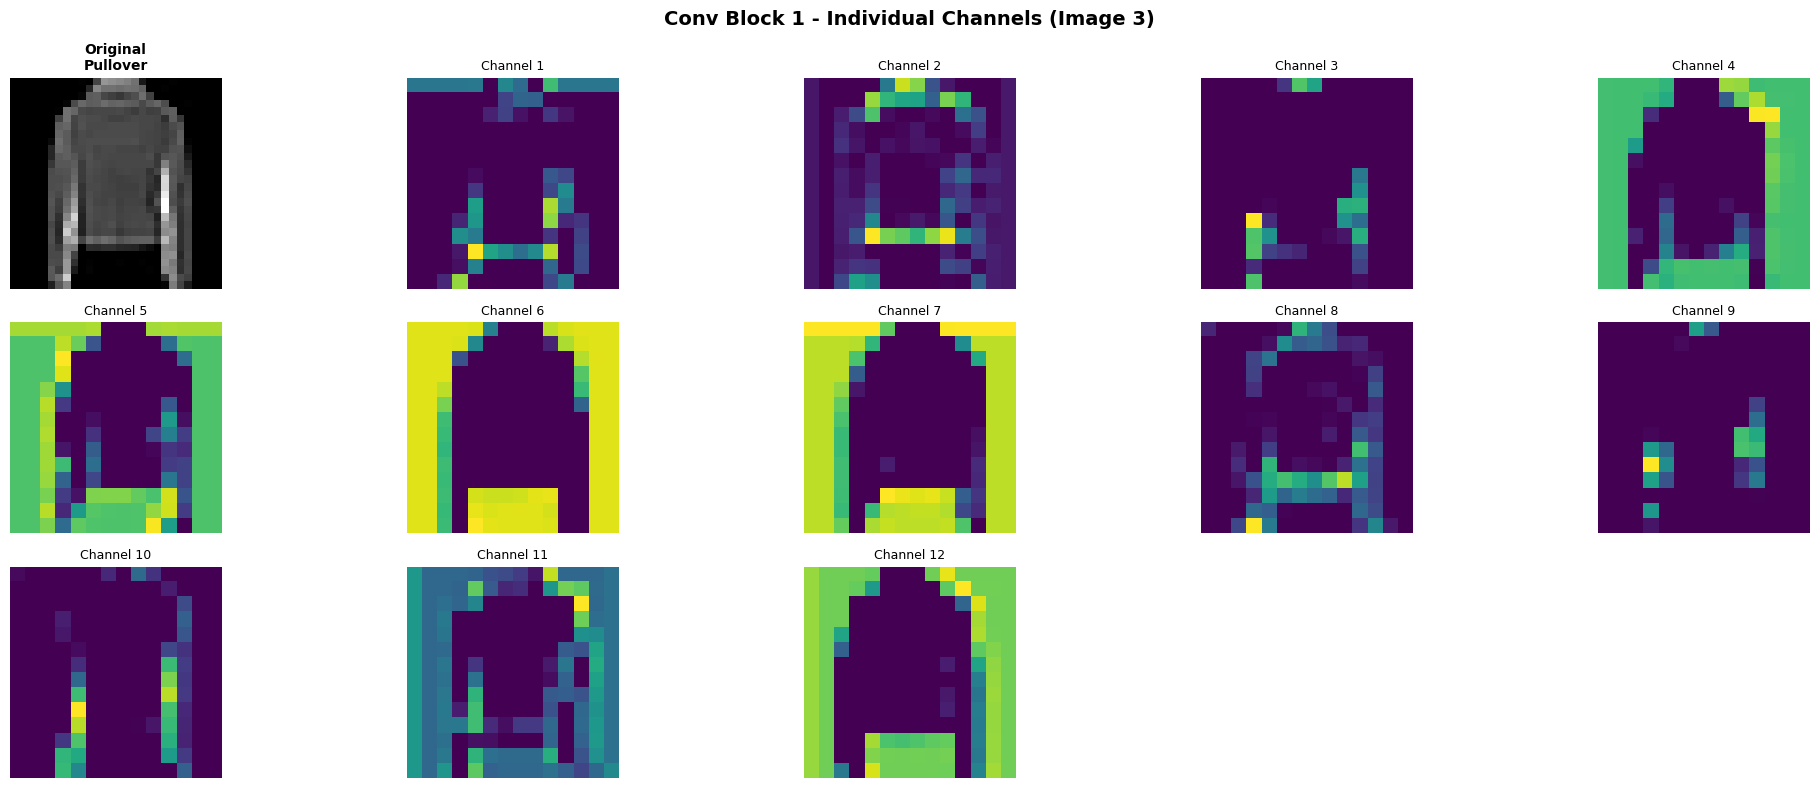

Saved INDIVIDUAL channels (Layer 2): plots/feature_maps_individual_img3_layer2.png


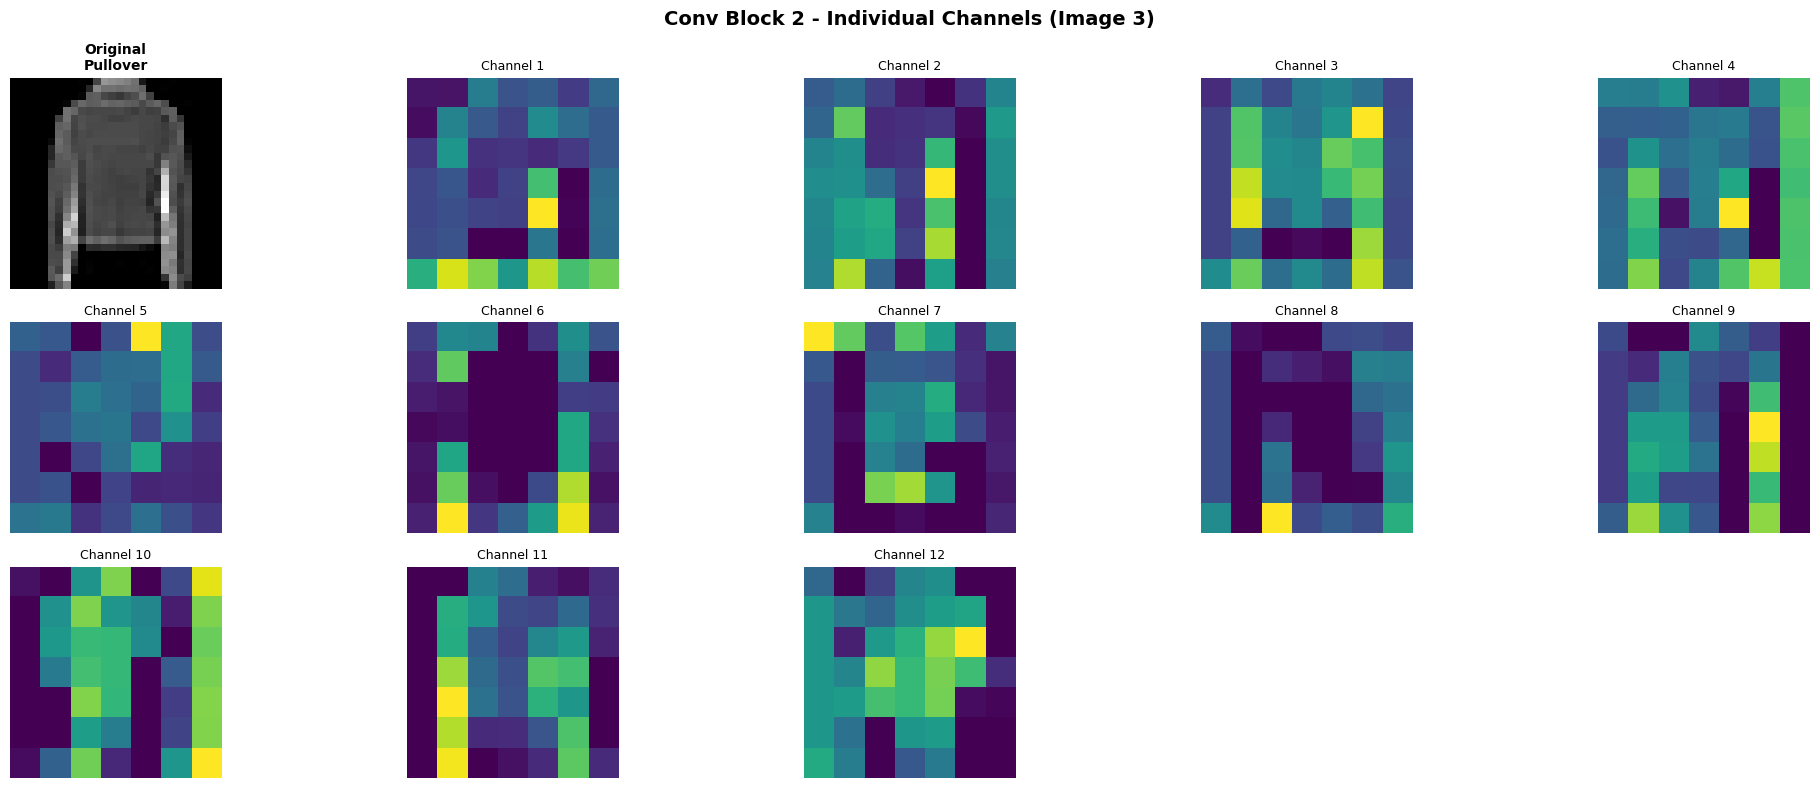

Saved INDIVIDUAL channels (Layer 3): plots/feature_maps_individual_img3_layer3.png


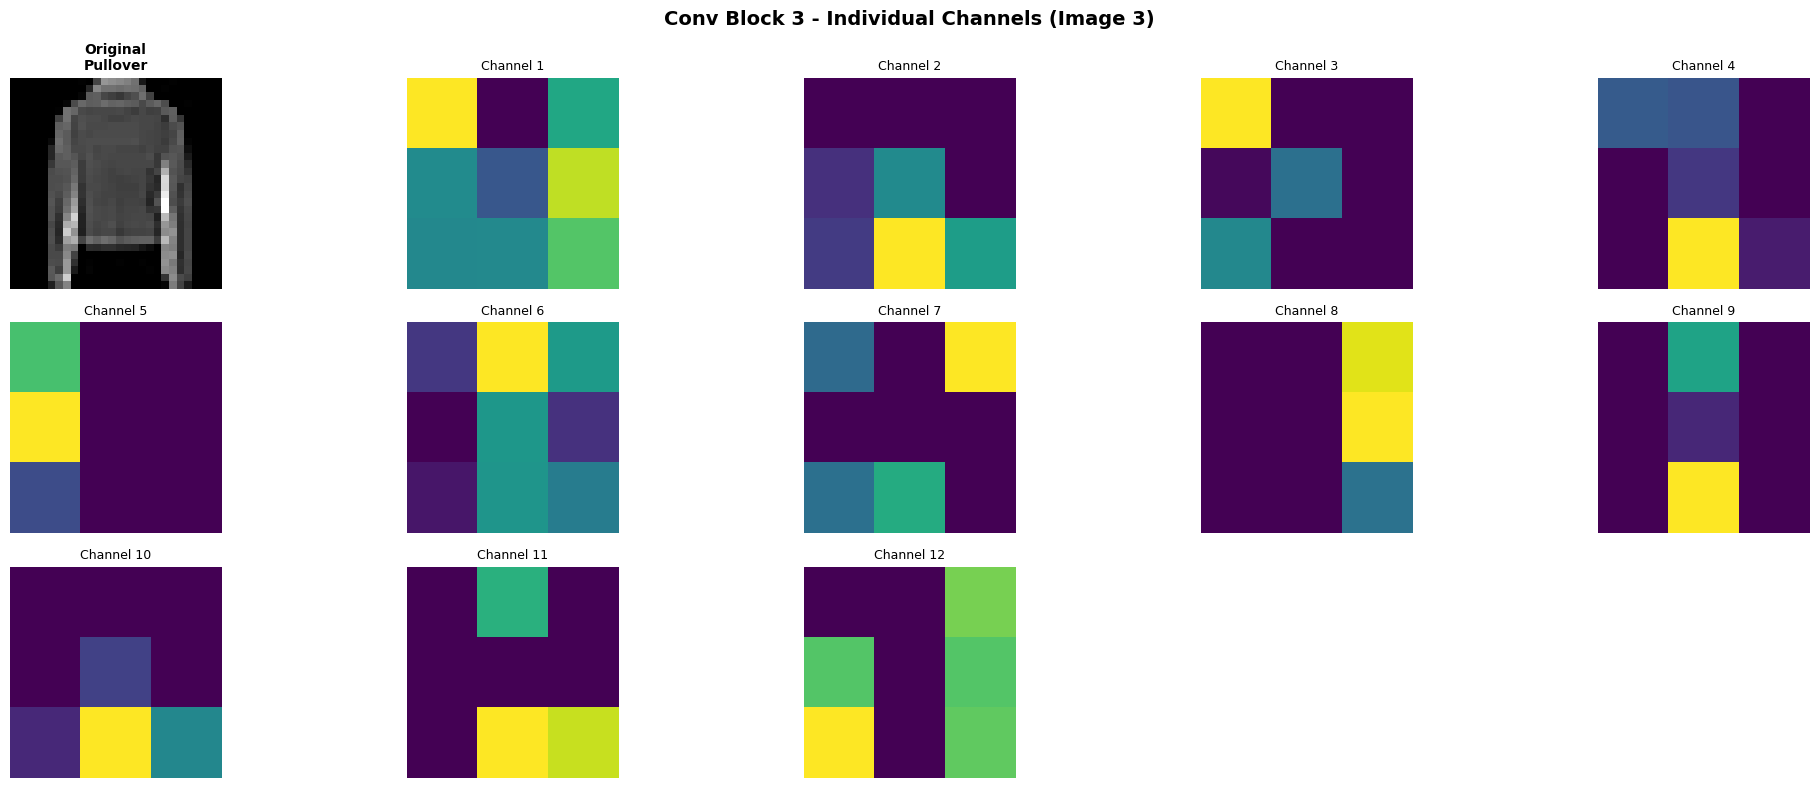

 Completed visualization for Image 3




ALL EXPERIMENTS COMPLETED!

Total experiments run: 28
Best classification accuracy: 0.9166
Best regression RMSE: 0.0183

All plots saved in 'plots/' directory
WandB logs available at: https://wandb.ai/



In [ ]:
# Feature Map Visualization for Best Model

"""
Visualize intermediate feature maps from the best classification model.
Shows both individual channels and combined grid views.
"""

print("\n" + "="*80)
print("FEATURE MAP VISUALIZATION - BEST MODEL")
print("="*80)

# Create test loader
test_transform = get_transforms(is_train=False)
test_ds = FashionMNISTDataset(test_dataset, transform=test_transform)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=True, num_workers=2)

wandb.init(project="SMAI_A4_Q1_MultiTask_re_run", name="Best_Model_Feature_Maps", reinit=True)

def visualize_feature_maps(model, test_loader, device='cuda', num_images=3):
    """Visualize feature maps from convolutional layers."""
    model.eval()
    
    images, labels, _ = next(iter(test_loader))
    images = images[:num_images].to(device)
    labels = labels[:num_images]
    
    class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
                   'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
    
    with torch.no_grad():
        _, _, feature_maps = model(images, return_features=True)
    
    # Denormalize images
    mean, std = 0.2860, 0.3530
    images_denorm = images.cpu() * std + mean
    images_denorm = torch.clamp(images_denorm, 0, 1)
    
    # Plot each image
    for img_idx in range(num_images):
        num_layers = len(feature_maps)
        
        print(f"\n--- Processing Test Image {img_idx+1}: {class_names[labels[img_idx]]} ---")
        
        fig = plt.figure(figsize=(20, 4))
        
        # Original image
        ax = plt.subplot(1, num_layers + 1, 1)
        plt.imshow(images_denorm[img_idx].squeeze(), cmap='gray')
        plt.title(f'Original\n{class_names[labels[img_idx]]}', 
                 fontsize=10, fontweight='bold')
        plt.axis('off')
        
        # Feature maps from each layer (GRID VIEW)
        for layer_idx, fmap in enumerate(feature_maps):
            ax = plt.subplot(1, num_layers + 1, layer_idx + 2)
            
            fmap_img = fmap[img_idx].detach().cpu()
            num_channels = min(12, fmap_img.shape[0])
            
            grid_size = int(np.ceil(np.sqrt(num_channels)))
            fmap_grid = np.zeros((grid_size * fmap_img.shape[1], 
                                 grid_size * fmap_img.shape[2]))
            
            for ch_idx in range(num_channels):
                row = ch_idx // grid_size
                col = ch_idx % grid_size
                fmap_grid[row*fmap_img.shape[1]:(row+1)*fmap_img.shape[1],
                         col*fmap_img.shape[2]:(col+1)*fmap_img.shape[2]] = fmap_img[ch_idx]
            
            plt.imshow(fmap_grid, cmap='viridis')
            plt.title(f'Conv Block {layer_idx+1}\n{fmap_img.shape[0]} channels\n(Grid View)', 
                     fontsize=10, fontweight='bold')
            plt.axis('off')
        
        plt.suptitle(f'Feature Maps Grid View - Test Image {img_idx+1}', 
                    fontsize=14, fontweight='bold', y=1.02)
        plt.tight_layout()
        
        save_path = f'plots/feature_maps_grid_img{img_idx+1}.png'
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved GRID view: {save_path}")
        wandb.log({f"feature_maps_grid_image_{img_idx+1}": wandb.Image(fig)})
        plt.show()
        
        for layer_idx, fmap in enumerate(feature_maps):
            fmap_img = fmap[img_idx].detach().cpu()
            num_channels = min(12, fmap_img.shape[0])
            
            fig = plt.figure(figsize=(20, 8))
            
            ax = plt.subplot(3, 5, 1)
            plt.imshow(images_denorm[img_idx].squeeze(), cmap='gray')
            plt.title(f'Original\n{class_names[labels[img_idx]]}', 
                     fontsize=10, fontweight='bold')
            plt.axis('off')
            
            for ch_idx in range(num_channels):
                ax = plt.subplot(3, 5, ch_idx + 2)
                plt.imshow(fmap_img[ch_idx], cmap='viridis')
                plt.title(f'Channel {ch_idx+1}', fontsize=9)
                plt.axis('off')
            
            for empty_idx in range(num_channels + 2, 15):
                ax = plt.subplot(3, 5, empty_idx)
                plt.axis('off')
            
            plt.suptitle(f'Conv Block {layer_idx+1} - Individual Channels (Image {img_idx+1})', 
                        fontsize=14, fontweight='bold')
            plt.tight_layout()
            
            save_path = f'plots/feature_maps_individual_img{img_idx+1}_layer{layer_idx+1}.png'
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"Saved INDIVIDUAL channels (Layer {layer_idx+1}): {save_path}")
            wandb.log({f"feature_maps_individual_img{img_idx+1}_layer{layer_idx+1}": wandb.Image(fig)})
            plt.show()
        
        print(f" Completed visualization for Image {img_idx+1}\n")

visualize_feature_maps(
    best_acc_result['trainer'].model,
    test_loader,
    device=device,
    num_images=3
)

wandb.finish()

print("\n" + "="*80)
print("ALL EXPERIMENTS COMPLETED!")
print("="*80)
print(f"\nTotal experiments run: {len(all_results)}")
print(f"Best classification accuracy: {best_acc_result['accuracy']:.4f}")
print(f"Best regression RMSE: {best_rmse_result['rmse']:.4f}")
print("\nAll plots saved in 'plots/' directory")
print("WandB logs available at: https://wandb.ai/")
print("="*80 + "\n")

## Wandb Dashboard 

### All experiments logged at: https://wandb.ai/tempakash48-iiit-hyderabad/SMAI_A4_Q1_MultiTask_re_run?nw=nwusertempakash48 